<center>
<img src='https://sharif.edu/~izadi/images/logo_sharif.png' alt="SUT logo" width=260 height=300 class="saturate">
</center>

<font face="Times New Roman">
    <div dir=ltr align=center>
        <font color=0F5298 size=7>
            Machine Learning Course Project
        </font>
        <br><br>
        <font color=2565AE size=5>
            Computer Engineering Department<br>Lecturer: Dr. Sharifi-Zarchi<br>Spring 2025
        </font>
        <br><br>
        <font color=3C99D size=5>
            Project 8: MVTec AD Anomaly Detection
        </font>
        <br><br>
        <font color=6EACDA size=4>
            Author: Amir Mohammad Fakhimi
        </font>
    </div>
    <br><br>
</font>

This notebook is a **course project template** for **MVTec AD anomaly detection**.

You will:

1. Run a **PaDiM baseline** (feature-statistics anomaly detection).
2. Implement **your own method** (student method) using **only `train/good`** for training.
3. Report **quantitative metrics** (per-category + overall) and **qualitative visualizations**.
4. Compare **PaDiM vs your method** on the *same* categories and test images.

> This notebook is intentionally "report-first": after each model runs, you call a small set of functions to get tables and plots.

## 0) Setup

### What you need
- Python + PyTorch + torchvision
- Common scientific stack (NumPy / pandas / matplotlib / scikit-learn)
- MVTec AD dataset extracted under `DATASET_ROOT`

### What you will get
- Per-category results (tables + bar plots)
- Overall results (macro mean across categories + micro over all test images)
- Qualitative overlays (input, anomaly map, overlay + GT contour)

In [1]:
import math
import random
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader, Dataset

import torchvision
from torchvision import transforms
from torchvision.models import resnet18, resnet34

from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

from IPython.display import display

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'mps' if torch.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'

NUM_WORKERS = 0
PIN_MEMORY = (DEVICE == 'cuda')

print('DEVICE:', DEVICE)

DEVICE: cuda


## 1) Download the dataset (MVTec AD)

This project uses the **MVTec Anomaly Detection (MVTec AD)** dataset.

1. Download the **whole dataset** (~4.9 GB) from the official downloads page:
   - https://www.mvtec.com/company/research/datasets/mvtec-ad/downloads

2. Extract it so you end up with a folder named `mvtec_anomaly_detection/` that contains the category folders:
   - `bottle/`, `cable/`, `capsule/`, ..., `zipper/`

Example (Linux/macOS):

```bash
# Put the downloaded archive in the same folder as this notebook
tar -xf mvtec_anomaly_detection.tar.xz
```

If you prefer a direct download link, the official site links to a `mydrive.ch` file under "Download the whole dataset".

In [3]:
DATASET_ROOT = Path('./mvtec_anomaly_detection')
DATASET_ROOT.mkdir(parents=True, exist_ok=True)

In [4]:
print('DATA_ROOT:', DATASET_ROOT.resolve())
print('Exists?', DATASET_ROOT.exists())

DATA_ROOT: D:\projectAP\Anomaly_Detection\mvtec_anomaly_detection
Exists? True


## 2) Dataset utilities

This section provides small helper functions to:
- list `.png` images in a directory
- collect MVTec paths for one category:
  - `train_good`
  - `test_good`
  - `test_anomaly`
  - a mapping from **test-relative key** → **GT mask path**

In [5]:
def list_images(directory_path: Path) -> List[Path]:
    """Return a sorted list of `.png` files inside `directory_path`."""
    if not directory_path.exists():
        return []

    return sorted([p for p in directory_path.iterdir() if p.is_file() and p.suffix.lower() == '.png'])


def mvtec_collect_category(category_directory: Path) -> Dict[str, object]:
    """Collect MVTec paths for one category.

    Returns a dict with:
      - train_good: List[Path]
      - test_good: List[Path]
      - test_anomaly: List[Path]
      - gt_masks_by_name: Dict[str, Path]

    The `gt_masks_by_name` key format is:
      '<defect_type>/<file_name>.png'  (relative to `test/`)

    This avoids filename collisions across defect types (e.g., `scratch/000.png` vs `contamination/000.png`).
    """
    train_good = list_images(category_directory / 'train' / 'good')

    test_good = list_images(category_directory / 'test' / 'good')
    test_anomaly: List[Path] = []
    gt_masks_by_name: Dict[str, Path] = {}

    test_directory = category_directory / 'test'
    gt_directory = category_directory / 'ground_truth'

    if test_directory.exists():
        for defect in sorted([p for p in test_directory.iterdir() if p.is_dir() and p.name != 'good']):
            test_anomaly.extend(list_images(defect))

    if gt_directory.exists():
        for defect in sorted([p for p in gt_directory.iterdir() if p.is_dir()]):
            for mask_path in list_images(defect):
                key = f"{defect.name}/{mask_path.name.replace('_mask', '')}"
                gt_masks_by_name[key] = mask_path

    return {
        'train_good': train_good,
        'test_good': test_good,
        'test_anomaly': sorted(test_anomaly),
        'gt_masks_by_name': gt_masks_by_name,
    }

## 3) Dataset + DataLoaders (6 points)

We wrap MVTec paths into a `Dataset` that returns:

- `image` (tensor, resized to 224×224)
- `label` (0 = good, 1 = anomaly)
- `mask` (binary tensor) if GT exists, otherwise `None`
- `image_path` (string)

We also define a collate function so the batch keeps `image_path` and `mask` fields.

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

In [7]:
padim_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# The VAE decoder uses Sigmoid, so its inputs must also be in [0, 1].
student_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])


In [8]:
class MVTecDataset(Dataset):
    """A minimal dataset wrapper for MVTec AD.

    Each item returns a dict:
      - image: FloatTensor (3, 224, 224)
      - label: LongTensor scalar (0=good, 1=anomaly)
      - mask: FloatTensor (1, 224, 224) with {0,1} values, or None (for good images)
      - image_path: str
    """

    def __init__(
        self,
        image_paths: List[Path],
        labels: List[int],
        mask_paths: Optional[List[Optional[Path]]] = None,
        transform=None,
    ):
        assert len(image_paths) == len(labels), "image_paths and labels must have the same length"
        if mask_paths is not None:
            assert len(mask_paths) == len(image_paths), "mask_paths must align with image_paths"

        # TODO (2 points)
        self.image_paths = list(image_paths)
        self.labels = list(labels)
        self.mask_paths = list(mask_paths) if mask_paths is not None else None
        self.transform = transform

    def __len__(self) -> int:
        """Number of items in the dataset."""
        # TODO (1 points)
        return len(self.image_paths)

    def __getitem__(self, index: int) -> Dict[str, object]:
        """Load one image (and optional mask) and return a dict."""
        # TODO (2 points)
        image_path = self.image_paths[index]
        label = int(self.labels[index])

        # Load image (MVTec is typically RGB, but ensure it)
        pil_img = Image.open(image_path).convert("RGB")

        # Apply transform (should output FloatTensor (3,224,224))
        if self.transform is not None:
            image = self.transform(pil_img)
        else:
            # fallback: do a basic resize->tensor if no transform provided
            image = TF.to_tensor(TF.resize(pil_img, [224, 224]))

        mask = None
        # Keep masks aligned with the resized image (224×224).
        # TODO (1 points)
        if self.mask_paths is not None:
            mp = self.mask_paths[index]
            if mp is not None and label == 1:  # anomaly
                pil_mask = Image.open(mp).convert("L")  # grayscale
                # Resize with NEAREST to avoid interpolating labels
                pil_mask = TF.resize(pil_mask, [224, 224], interpolation=TF.InterpolationMode.NEAREST)

                mask = TF.to_tensor(pil_mask)  # (1,H,W) in [0,1] usually
                # Binarize to {0,1}
                mask = (mask > 0.5).float()
            # else: keep mask None for good images (or missing mask)

        return {
            "image": image,
            "label": torch.tensor(label, dtype=torch.long),
            "mask": mask,
            "image_path": str(image_path),
        }


In [9]:
def mvtec_collate_fn(batch: List[Dict[str, object]]) -> Dict[str, object]:
    """Collate function that keeps image paths and (optional) masks in the batch."""
    images = torch.stack([b['image'] for b in batch], dim=0)
    labels = torch.stack([b['label'] for b in batch], dim=0)
    paths = [b['image_path'] for b in batch]
    masks = [b['mask'] for b in batch]

    return {'image': images, 'label': labels, 'image_path': paths, 'mask': masks}

## 4) Dataset sanity checks (stats + visuals)

Before running models, we:
- check basic dataset counts per category
- pick **fixed samples** (good + anomaly with GT available)
- visualize those samples so qualitative results are consistent across runs

In [10]:
def get_categories(data_root: Path) -> List[str]:
    """Return category folder names under `data_root` (e.g., 'bottle', 'cable', ...)."""
    if not data_root.exists():
        return []

    return sorted([p.name for p in data_root.iterdir() if p.is_dir() and not p.name.startswith('.')])

In [11]:
CATEGORIES = get_categories(DATASET_ROOT)

print('Num categories:', len(CATEGORIES))
print('First 5:', CATEGORIES[:5])

Num categories: 15
First 5: ['bottle', 'cable', 'capsule', 'carpet', 'grid']


In [12]:
def select_fixed_samples_by_category(
    dataset_root: Path,
    categories: List[str],
    seed: int = 0,
    n_good: int = 1,
    n_anom: int = 1,
) -> Dict[str, List[str]]:
    """Select fixed sample image paths per category for qualitative visualization.

    We pick:
      - `n_good` images from `test/good`
      - `n_anom` images from anomaly folders in `test/` **only if a GT mask exists**

    Returns:
        Dict[category -> List[path_str]] (good samples first, then anomalies).
    """
    rng = np.random.RandomState(seed)
    out: Dict[str, List[str]] = {}

    for category in categories:
        data = mvtec_collect_category(dataset_root / category)
        good_paths: List[Path] = list(data['test_good'])
        anomaly_paths: List[Path] = list(data['test_anomaly'])
        gt_by_name: Dict[str, Path] = dict(data['gt_masks_by_name'])

        # Keep only anomalies that have GT masks (so contours/metrics are meaningful).
        anomaly_paths = [
            p for p in anomaly_paths
            if str(p.relative_to(dataset_root / category / 'test')).replace('\\', '/') in gt_by_name
        ]

        sel: List[str] = []

        if n_good > 0 and len(good_paths) > 0:
            g_idx = rng.choice(len(good_paths), size=min(n_good, len(good_paths)), replace=False)
            sel.extend([str(good_paths[j]) for j in g_idx])

        if n_anom > 0 and len(anomaly_paths) > 0:
            a_idx = rng.choice(len(anomaly_paths), size=min(n_anom, len(anomaly_paths)), replace=False)
            sel.extend([str(anomaly_paths[j]) for j in a_idx])

        out[category] = sel

    return out

In [13]:
QUAL_SAMPLE_PATHS_BY_CAT = select_fixed_samples_by_category(
    DATASET_ROOT, CATEGORIES, seed=SEED, n_good=1, n_anom=1
)

print('Example qualitative samples (first 3 categories):')
for c in CATEGORIES[:3]:
    print(' -', c, '->', [Path(p).name for p in QUAL_SAMPLE_PATHS_BY_CAT[c]])

Example qualitative samples (first 3 categories):
 - bottle -> ['000.png', '004.png']
 - cable -> ['045.png', '002.png']
 - capsule -> ['011.png', '018.png']


In [14]:
def category_stats(category: str) -> Dict[str, object]:
    """Compute a few quick dataset statistics for one MVTec category."""
    category_data = mvtec_collect_category(DATASET_ROOT / category)
    defect_types = sorted({Path(p).parent.name for p in category_data['test_anomaly']})

    return {
        'category': category,
        'train_good': len(category_data['train_good']),
        'test_good': len(category_data['test_good']),
        'test_anomaly': len(category_data['test_anomaly']),
        'num_defect_types': len(defect_types),
        'defect_types': ', '.join(defect_types),
    }

In [15]:
if len(CATEGORIES):
    df_stats = pd.DataFrame([category_stats(c) for c in CATEGORIES])
    display(df_stats)
else:
    print('No categories found. Check DATA_ROOT.')

,category,train_good,test_good,test_anomaly,num_defect_types,defect_types
0,bottle,209,20,63,3,"broken_large, broken_small, contamination"
1,cable,224,58,92,8,"bent_wire, cable_swap, combined, cut_inner_ins..."
2,capsule,219,23,109,5,"crack, faulty_imprint, poke, scratch, squeeze"
3,carpet,280,28,89,5,"color, cut, hole, metal_contamination, thread"
4,grid,264,21,57,5,"bent, broken, glue, metal_contamination, thread"
5,hazelnut,391,40,70,4,"crack, cut, hole, print"
6,leather,245,32,92,5,"color, cut, fold, glue, poke"
7,metal_nut,220,22,93,4,"bent, color, flip, scratch"
8,pill,267,26,141,7,"color, combined, contamination, crack, faulty_..."
9,screw,320,41,119,5,"manipulated_front, scratch_head, scratch_neck,..."


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\3853985556.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


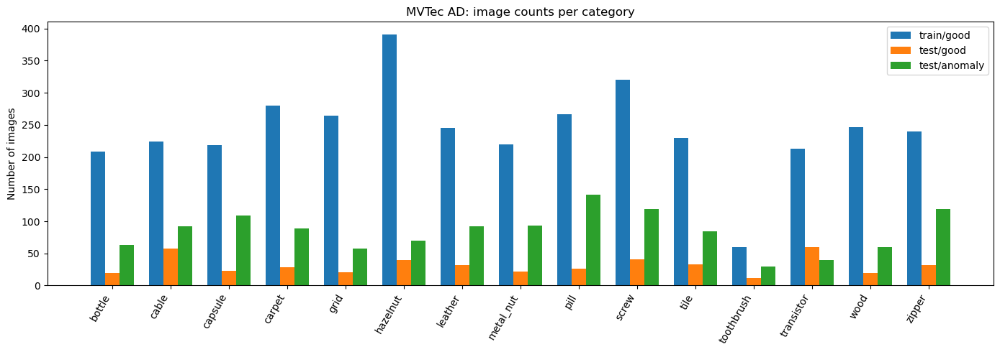

In [16]:
if 'df_stats' in globals() and len(df_stats):
    x = np.arange(len(df_stats))
    width = 0.25
    plt.figure(figsize=(14, 5))

    plt.bar(x - width, df_stats['train_good'].values, width=width, label='train/good')
    plt.bar(x, df_stats['test_good'].values, width=width, label='test/good')
    plt.bar(x + width, df_stats['test_anomaly'].values, width=width, label='test/anomaly')

    plt.xticks(x, df_stats['category'].values, rotation=60, ha='right')
    plt.ylabel('Number of images')

    plt.title('MVTec AD: image counts per category')
    plt.legend()
    plt.tight_layout()
    plt.show()

In [17]:
def show_fixed_samples(category: str) -> None:
    """Show the fixed qualitative samples (good + anomaly) picked for a category."""
    sample_paths = QUAL_SAMPLE_PATHS_BY_CAT.get(category, [])
    if not sample_paths:
        print('No fixed samples for', category, '(QUAL_SAMPLE_PATHS_BY_CAT empty).')
        return

    samples = []
    for p in sample_paths:
        p = str(p)
        tag = 'good' if Path(p).parent.name == 'good' else 'anomaly'
        samples.append((tag, p))

    cols = min(4, len(samples))
    rows = int(math.ceil(len(samples) / cols))

    plt.figure(figsize=(12, 3.5 * rows))
    for i, (tag, p) in enumerate(samples, 1):
        img = Image.open(p).convert('RGB')
        plt.subplot(rows, cols, i)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f'{category} | {tag}')

    plt.tight_layout()
    plt.show()

C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1631731820.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


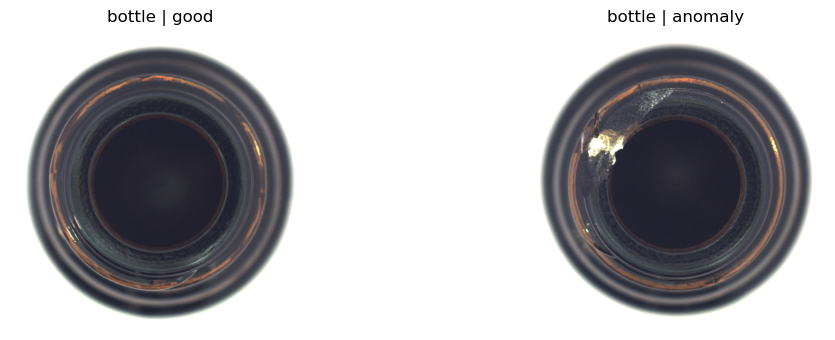

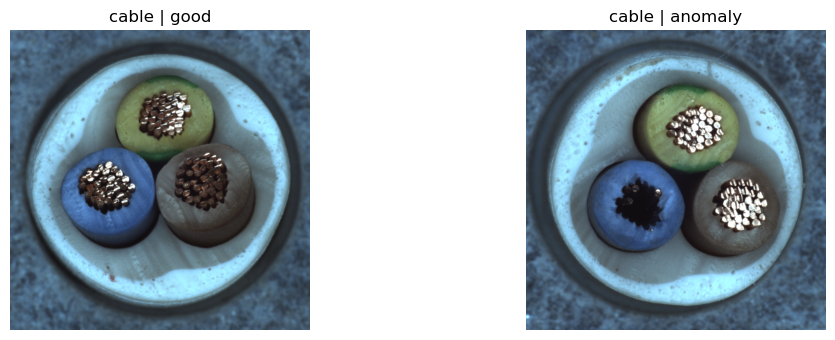

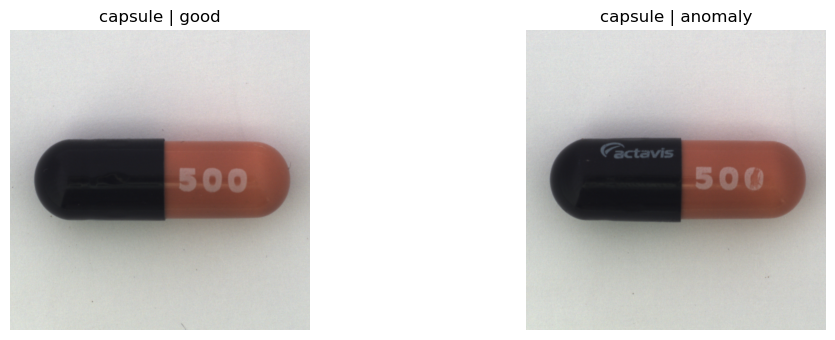

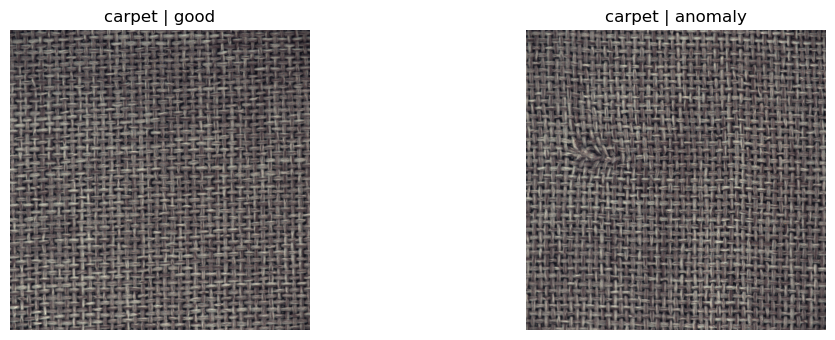

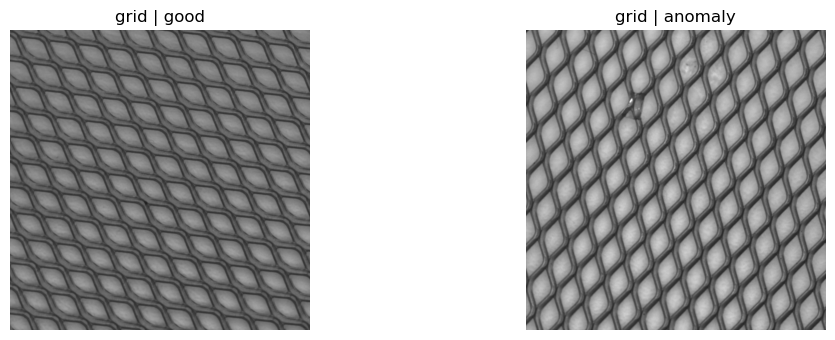

...

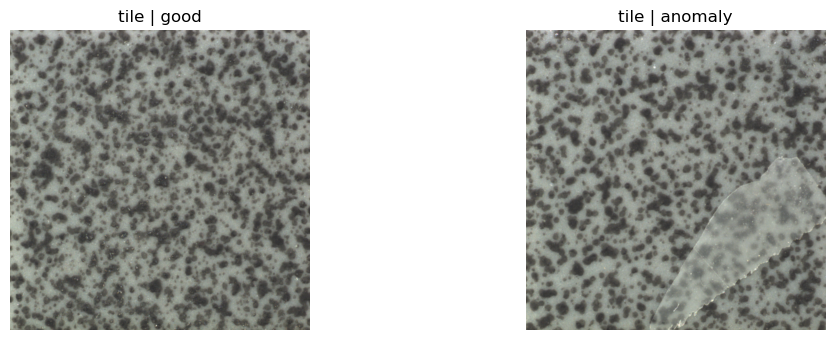

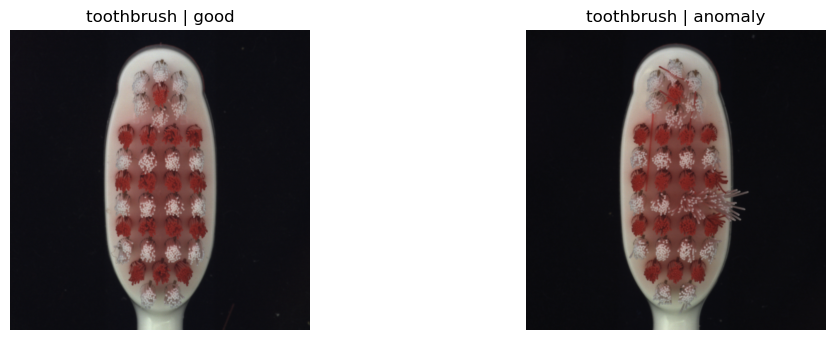

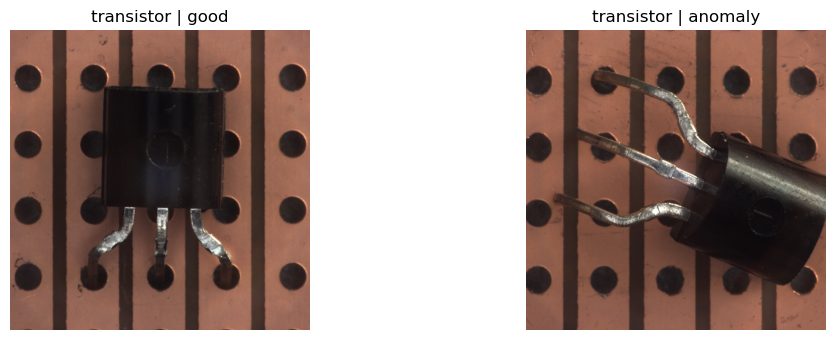

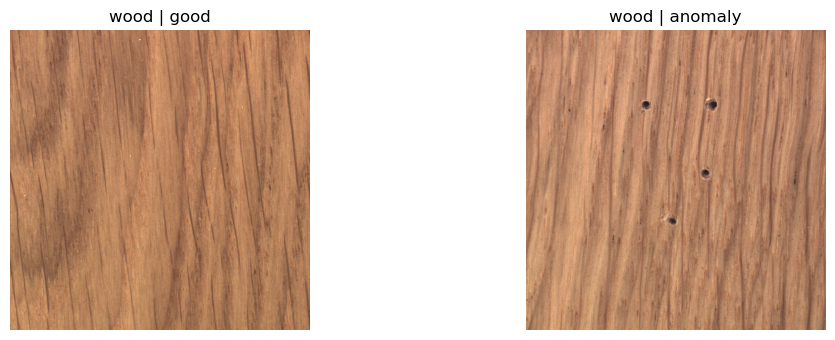

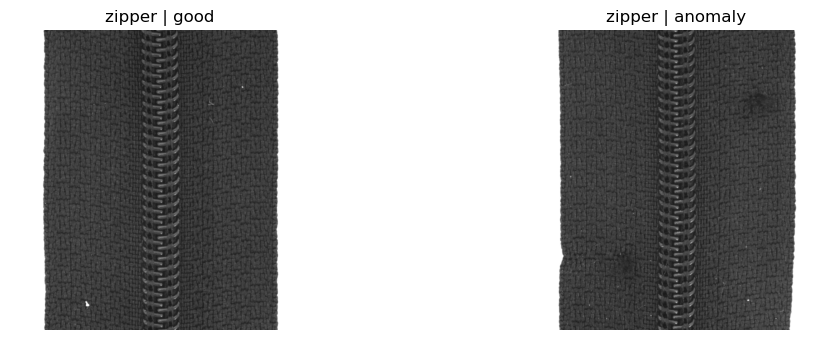

In [18]:
if len(CATEGORIES):
    for category in CATEGORIES:
        show_fixed_samples(category)

## 5) PaDiM baseline implementation (30 points)

PaDiM (Patch Distribution Modeling) builds a **Gaussian model** over deep features extracted from a pretrained backbone.

High-level steps per category:
1. Extract intermediate backbone features on `train/good`
2. Build per-location feature distribution (mean + covariance)
3. Score each test image by **Mahalanobis distance** to the learned distribution
4. Produce:
   - pixel-level anomaly map
   - image-level score (aggregation of top anomaly pixels)

In [19]:
import torchvision.models as models


class ResNetFeatureExtractor(nn.Module):
    """Extract intermediate feature maps from a pretrained ResNet backbone.

    Args:
        backbone: 'resnet18' or 'resnet34'
        pretrained: whether to load ImageNet weights
        layers: which layer feature maps to return (e.g., ('layer1','layer2','layer3'))
    """

    def __init__(
        self,
        backbone: str = 'resnet18',
        pretrained: bool = True,
        layers: Tuple[str, ...] = ('layer1', 'layer2', 'layer3'),
    ):
        """Initialize the backbone and register which layers to return."""
        super().__init__()

        if backbone == 'resnet18':
            # TODO (1 point)
            self.backbone = models.resnet18(pretrained=pretrained)
        elif backbone == 'resnet34':
            # TODO (1 point)
            self.backbone = models.resnet34(pretrained=pretrained)
        else:
            raise ValueError('Unsupported backbone: ' + backbone)

        # Remove classification head
        self.backbone.fc = nn.Identity()
        self.backbone.avgpool = nn.Identity()

        # TODO (1 point)
        self.layers = layers

    def forward(self, x: torch.Tensor) -> List[torch.Tensor]:
        """Return a list of feature maps, ordered as `self.layers`."""

        features = {}

        # Stem
        x = self.backbone.conv1(x)
        x = self.backbone.bn1(x)
        x = self.backbone.relu(x)
        x = self.backbone.maxpool(x)

        # Residual layers
        x = self.backbone.layer1(x)
        features['layer1'] = x

        x = self.backbone.layer2(x)
        features['layer2'] = x

        x = self.backbone.layer3(x)
        features['layer3'] = x

        x = self.backbone.layer4(x)
        features['layer4'] = x

        # TODO (3 points)
        return [features[k] for k in self.layers]


In [20]:
def align_and_concat_features(
    feature_list: List[torch.Tensor],
    target_hw: Tuple[int, int] = (28, 28),
) -> torch.Tensor:
    """Resize feature maps to `target_hw` and concatenate them along channel dimension.

    This produces a single embedding tensor of shape (B, C_total, H, W).
    """
    aligned = []
    for f in feature_list:
        if f.shape[-2:] != target_hw:
            f = F.interpolate(f, size=target_hw, mode='bilinear', align_corners=False)
        aligned.append(f)
    return torch.cat(aligned, dim=1)

In [21]:
def build_channel_indices(total_channels: int, d: int, seed: int = 0) -> np.ndarray:
    """Select `d` channels out of `total_channels` (deterministic given `seed`)."""
    rng = np.random.RandomState(seed)
    if d >= total_channels:
        return np.arange(total_channels)
    index = rng.choice(total_channels, size=d, replace=False)

    return np.sort(index)

In [22]:
def extract_embeddings(
    feature_model: nn.Module,
    loader: DataLoader,
    channel_index: Optional[np.ndarray],
    target_hw: Tuple[int, int],
    device: str,
) -> Tuple[torch.Tensor, List[str], List[int], List[object]]:
    """Extract aligned embeddings for all images in a loader.

    Returns:
        embeddings: Tensor (N, C, H, W) on CPU
        paths: list of image path strings
        labels: list of int labels (0/1)
        masks: list of masks (tensor or None), aligned with paths
    """
    feature_model.eval()

    all_embs: List[torch.Tensor] = []
    all_paths: List[str] = []
    all_labels: List[int] = []
    all_masks: List[object] = []

    Ht, Wt = target_hw

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device, non_blocking=True)          # (B,3,224,224)
            labels = batch["label"]                                       # (B,) or list
            paths = batch["image_path"]                                   # list[str] or tuple[str]

            # masks can be:
            #  - None
            #  - a tensor (B,1,224,224)
            #  - a list length B with tensors/None (common with default collate)
            masks = batch.get("mask", None)

            feats = feature_model(images)
            if isinstance(feats, torch.Tensor):
                feats = [feats]

            # resize each feature map to target_hw then concat on channel dim
            resized = [
                F.interpolate(f, size=(Ht, Wt), mode="bilinear", align_corners=False)
                for f in feats
            ]
            emb = torch.cat(resized, dim=1)  # (B, C_total, Ht, Wt)

            # optional channel selection
            if channel_index is not None:
                idx = torch.as_tensor(channel_index, dtype=torch.long, device=emb.device)
                emb = emb.index_select(dim=1, index=idx)

            all_embs.append(emb.detach().cpu())

            # collect metadata
            if torch.is_tensor(labels):
                all_labels.extend([int(x) for x in labels.detach().cpu().tolist()])
            else:
                all_labels.extend([int(x) for x in labels])

            all_paths.extend([str(p) for p in paths])

            # align masks to target_hw (nearest, keep None as None)
            if masks is None:
                all_masks.extend([None] * images.size(0))
            elif torch.is_tensor(masks):
                # (B,1,H,W)
                m = masks.float()
                m = F.interpolate(m, size=(Ht, Wt), mode="nearest")
                m = (m > 0.5).float()
                all_masks.extend([m[i].cpu() for i in range(m.size(0))])
            else:
                # list/tuple of per-sample masks (tensor or None)
                for m in masks:
                    if m is None:
                        all_masks.append(None)
                    else:
                        mm = m
                        if mm.dim() == 2:
                            mm = mm.unsqueeze(0)  # (1,H,W)
                        if mm.dim() == 3:
                            mm = mm.unsqueeze(0)  # (1,1,H,W)
                        mm = mm.float()
                        mm = F.interpolate(mm, size=(Ht, Wt), mode="nearest")
                        mm = (mm > 0.5).float()
                        all_masks.append(mm.squeeze(0).cpu())  # (1,Ht,Wt)

    embeddings = torch.cat(all_embs, dim=0) if len(all_embs) else torch.empty(0)
    return embeddings, all_paths, all_labels, all_masks


In [23]:
def fit_padim_gaussian(
    train_embeddings: torch.Tensor,
    cov_eps: float = 1e-3
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Fit per-location Gaussian parameters for PaDiM.

    Args:
        train_embeddings: Tensor (N, C, H, W) from train/good images.
        cov_eps: Small diagonal jitter for numerical stability.

    Returns:
        mu_map: Tensor (C, H, W) mean feature at each location.
        cov_inv: Tensor (H*W, C, C) inverse covariance per location.
    """
    assert train_embeddings.dim() == 4, "Expected (N, C, H, W)"
    N, C, H, W = train_embeddings.shape
    device = train_embeddings.device
    dtype = train_embeddings.dtype

    # Mean per spatial location: (C, H, W)
    mu_map = train_embeddings.mean(dim=0)

    # Reshape to (N, L, C) where L = H*W
    L = H * W
    X = train_embeddings.permute(0, 2, 3, 1).contiguous().view(N, L, C)   # (N, L, C)
    mu = mu_map.permute(1, 2, 0).contiguous().view(L, C)                 # (L, C)

    # Center: (N, L, C)
    Xc = X - mu.unsqueeze(0)

    # Covariance per location: (L, C, C)
    # cov[l] = (Xc[:,l,:]^T Xc[:,l,:]) / (N-1)
    denom = max(N - 1, 1)
    cov = torch.einsum("nlc,nld->lcd", Xc, Xc) / float(denom)

    # Add diagonal jitter for stability
    eye = torch.eye(C, device=device, dtype=dtype).unsqueeze(0)  # (1,C,C)
    cov = cov + cov_eps * eye

    # Invert covariance per location: (L, C, C)
    cov_inv = torch.linalg.inv(cov)

    return mu_map, cov_inv


In [24]:
def padim_score_maps(
    test_embeddings: torch.Tensor,
    mu_map: torch.Tensor,
    cov_inv: torch.Tensor
) -> torch.Tensor:
    """Compute PaDiM anomaly score maps (Mahalanobis distance) for test embeddings.

    Returns:
        score_maps: Tensor (N, H, W) where higher values indicate more anomalous pixels.
    """
    assert test_embeddings.dim() == 4, "test_embeddings must be (N,C,H,W)"
    n, c, h, w = test_embeddings.shape
    assert mu_map.shape == (c, h, w), f"mu_map must be (C,H,W), got {mu_map.shape}"
    assert cov_inv.shape == (h * w, c, c), f"cov_inv must be (H*W,C,C), got {cov_inv.shape}"

    # Flatten spatial dims to L = H*W
    L = h * w
    X = test_embeddings.permute(0, 2, 3, 1).contiguous().view(n, L, c)   # (N,L,C)
    mu = mu_map.permute(1, 2, 0).contiguous().view(L, c)                # (L,C)

    # Difference (N,L,C)
    diff = X - mu.unsqueeze(0)

    # Mahalanobis^2: d^2 = diff^T * Sigma^{-1} * diff  -> (N,L)
    # First: (N,L,C) x (L,C,C) -> (N,L,C)
    tmp = torch.einsum("nlc,lcd->nld", diff, cov_inv)
    scores = torch.einsum("nlc,nlc->nl", tmp, diff)  # (N,L)

    # Numerical safety: distances should be >= 0
    scores = torch.clamp(scores, min=0.0)

    return scores.reshape(n, h, w)


In [25]:
def normalize_01(x: np.ndarray) -> np.ndarray:
    """Normalize an array to [0, 1] (safe for constant arrays)."""
    x = x.astype(np.float32)
    mn, mx = float(x.min()), float(x.max())
    if mx - mn < 1e-12:
        return np.zeros_like(x)
    return (x - mn) / (mx - mn)


def aggregate_image_score(score_map: np.ndarray, aggregation: str = 'mean_topk', topk_frac: float = 0.1) -> float:
    """Aggregate a pixel anomaly map into a single image-level score."""
    s = score_map.reshape(-1)

    if aggregation == 'max':
        return float(s.max())
    if aggregation == 'mean':
        return float(s.mean())
    if aggregation == 'mean_topk':
        k = max(1, int(topk_frac * len(s)))
        return float(np.mean(np.partition(s, -k)[-k:]))

    raise ValueError('Unknown aggregation: ' + aggregation)

In [26]:
@dataclass
class PadimConfig:
    """Configuration for running PaDiM on a single MVTec category."""

    category: str
    backbone: str = 'resnet18'
    pretrained: bool = True
    layers: Tuple[str, ...] = ('layer1', 'layer2', 'layer3')
    target_hw: Tuple[int, int] = (28, 28)

    # Random channel subsampling (PaDiM uses a subset of channels for efficiency)
    d: int = 100

    # Gaussian fitting stability
    covariance_epsilon: float = 1e-3

    # Optional post-processing on anomaly maps
    smooth_sigma: Optional[float] = 2.0  # set None to disable smoothing

    # Image score aggregation
    image_aggregation: str = 'mean_topk'
    topk_fraction: float = 0.1

    # DataLoader settings
    batch_size: int = 32


def gaussian_smooth_np(m: np.ndarray, sigma: float) -> np.ndarray:
    """Apply a simple separable Gaussian blur to a 2D numpy array."""
    radius = int(3 * sigma)
    if radius <= 0:
        return m.astype(np.float32)

    xs = np.arange(-radius, radius + 1)
    k = np.exp(-(xs ** 2) / (2 * sigma ** 2))
    k = (k / k.sum()).astype(np.float32)

    # Convolve over height
    tmp = np.pad(m, ((radius, radius), (0, 0)), mode='reflect')
    out = np.zeros_like(m, dtype=np.float32)
    for i in range(m.shape[0]):
        out[i] = (tmp[i:i + 2 * radius + 1] * k[:, None]).sum(axis=0)

    # Convolve over width
    tmp2 = np.pad(out, ((0, 0), (radius, radius)), mode='reflect')
    out2 = np.zeros_like(out, dtype=np.float32)
    for j in range(out.shape[1]):
        out2[:, j] = (tmp2[:, j:j + 2 * radius + 1] * k[None, :]).sum(axis=1)

    return out2

In [27]:



def run_padim_category(config: PadimConfig) -> Dict[str, object]:
    """Run PaDiM on one category and return a result dict used by the reporting code."""
    t0 = time.time()

    d = mvtec_collect_category(DATASET_ROOT / config.category)
    train_paths = d['train_good']
    test_paths = d['test_good'] + d['test_anomaly']
    test_labels = [0] * len(d['test_good']) + [1] * len(d['test_anomaly'])

    mask_paths = []
    for p, y in zip(test_paths, test_labels):
        if y == 0:
            mask_paths.append(None)
        else:
            rel_key = str(Path(p).relative_to(DATASET_ROOT / config.category / 'test')).replace('\\', '/')
            mask_paths.append(d['gt_masks_by_name'].get(rel_key, None))

    train_dataset = MVTecDataset(train_paths, labels=[0] * len(train_paths), mask_paths=None, transform=padim_transform)
    test_dataset = MVTecDataset(test_paths, labels=test_labels, mask_paths=mask_paths, transform=padim_transform)

    train_loader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=False, num_workers=NUM_WORKERS,
                              pin_memory=PIN_MEMORY, collate_fn=mvtec_collate_fn)
    test_loader = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False, num_workers=NUM_WORKERS,
                             pin_memory=PIN_MEMORY, collate_fn=mvtec_collate_fn)

    feature_model = ResNetFeatureExtractor(backbone=config.backbone, pretrained=config.pretrained, layers=config.layers).to(DEVICE)
    # -------------------------------------------------------
    # Build PaDiM channel index (since config.channel_index does not exist)
    # -------------------------------------------------------
    feature_model.eval()
    with torch.no_grad():
        batch0 = next(iter(train_loader))
        x0 = batch0["image"].to(DEVICE, non_blocking=True)
        feats0 = feature_model(x0)
        if isinstance(feats0, torch.Tensor):
            feats0 = [feats0]
        emb0 = align_and_concat_features(feats0, target_hw=config.target_hw)
        total_channels = emb0.shape[1]

    channel_index = build_channel_indices(total_channels, d=config.d, seed=SEED)

    

    # TODO (4 points)
    # 1) extract train embeddings (good only)
    train_embs, _, _, _ = extract_embeddings(
        feature_model=feature_model,
        loader=train_loader,
        channel_index=channel_index,
        target_hw=config.target_hw,
        device=DEVICE,
    )

    # 2) fit PaDiM Gaussian (mu + per-location cov inverse)
    mu_map, cov_inv = fit_padim_gaussian(
    train_embs.to(DEVICE),
    cov_eps=config.covariance_epsilon
    )   

    # 3) extract test embeddings (good + anomaly) + metadata
    test_embs, paths, labels_out, masks_out = extract_embeddings(
        feature_model=feature_model,
        loader=test_loader,
        channel_index=channel_index,
        target_hw=config.target_hw,
        device=DEVICE,
    )

    # 4) compute score maps and move to numpy for downstream metrics/plots
    score_maps = padim_score_maps(test_embs.to(DEVICE), mu_map.to(DEVICE), cov_inv.to(DEVICE)).detach().cpu().numpy()

    scores = [aggregate_image_score(score_maps[i], aggregation=config.image_aggregation, topk_frac=config.topk_fraction)
              for i in
              range(len(score_maps))]
    scores = normalize_01(np.array(scores))

    img_m = image_metrics(labels_out, scores.tolist())

    pixel_aucs = []
    best_dices = []
    for i in range(len(labels_out)):
        if labels_out[i] == 1 and masks_out[i] is not None:
            gt = masks_out[i].numpy().squeeze(0)
            pixel_aucs.append(compute_pixel_auc(gt, score_maps[i]))
            best_dices.append(compute_best_dice(gt, normalize_01(score_maps[i])))

    pix_auc = float(np.nanmean(pixel_aucs)) if len(pixel_aucs) else float('nan')
    dice = float(np.nanmean(best_dices)) if len(best_dices) else float('nan')

    out = {
        'category': config.category,
        'image_metrics': img_m,
        'pixel_auroc': pix_auc,
        'pixel_best_dice': dice,
        'paths': paths,
        'labels': labels_out,
        'scores': scores.tolist(),
        'score_maps': score_maps,
        'masks': masks_out,
        'runtime_sec': float(time.time() - t0),
        'config': config,
    }
    return out


## 6) Student implementation (60 points)

Implement your own anomaly detection method with the same interface:

- `fit(train_loader)` uses **only `train/good`**
- `predict(test_loader)` must return:
  - `paths`: list of test paths in the same order as the loader
  - `scores`: anomaly scores (higher = more anomalous)
  - `score_maps`: pixel anomaly maps aligned with `paths` (required for pixel metrics + qualitative overlays)

In [28]:
import time
from typing import Dict, List, Tuple
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------- helper utils ----------
def _normalize_01(x: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    mn, mx = float(np.min(x)), float(np.max(x))
    if mx - mn < eps:
        return np.zeros_like(x, dtype=np.float32)
    return (x - mn) / (mx - mn)

def _aggregate_image_score(score_map: np.ndarray, mode: str = "topk", topk_frac: float = 0.01) -> float:
    sm = np.asarray(score_map, dtype=np.float32).reshape(-1)
    if sm.size == 0:
        return 0.0
    if mode == "max":
        return float(np.max(sm))
    if mode == "mean":
        return float(np.mean(sm))
    if mode == "topk":
        k = max(1, int(round(topk_frac * sm.size)))
        vals = np.partition(sm, -k)[-k:]
        return float(np.mean(vals))
    return float(np.max(sm))


# ---------- a small convolutional VAE ----------
class ConvVAE(nn.Module):
    """
    Conv VAE for 224x224 RGB images.
    Produces a latent vector z of size latent_dim, reconstructs back to image.
    """
    def __init__(self, latent_dim: int = 128):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder: (3,224,224) -> feature map
        self.enc = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),  # 112
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 4, stride=2, padding=1), # 56
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),# 28
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),# 14
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 4, stride=2, padding=1),# 7
            nn.ReLU(inplace=True),
        )
        # flattened size: 256*7*7
        self.flat_dim = 256 * 7 * 7
        self.fc_mu = nn.Linear(self.flat_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flat_dim, latent_dim)

        # Decoder: latent -> feature map -> image
        self.fc_dec = nn.Linear(latent_dim, self.flat_dim)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256, 256, 4, stride=2, padding=1), # 14
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 28
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 56
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),   # 112
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),    # 224
            nn.Sigmoid(),  # because inputs typically in [0,1]
        )

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        h = self.enc(x)
        h = h.view(x.size(0), -1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        h2 = self.fc_dec(z).view(x.size(0), 256, 7, 7)
        x_hat = self.dec(h2)
        return x_hat, mu, logvar


def vae_loss(x: torch.Tensor, x_hat: torch.Tensor, mu: torch.Tensor, logvar: torch.Tensor,
             recon_mode: str = "l1", beta: float = 1.0) -> torch.Tensor:
    # reconstruction
    if recon_mode == "mse":
        recon = F.mse_loss(x_hat, x, reduction="mean")
    else:
        recon = F.l1_loss(x_hat, x, reduction="mean")

    # KL divergence (mean over batch)
    # KL(q(z|x) || N(0,1)) = -0.5 * sum(1 + logvar - mu^2 - exp(logvar))
    kl = -0.5 * torch.mean(torch.sum(1.0 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    return recon + beta * kl


# ---------- StudentMethod ----------
class StudentMethod:
    """
    VAE-based anomaly detector.

    - fit(): train VAE on train/good images only
    - predict(): reconstruction error map -> score_maps + image scores
    """
    def __init__(
        self,
        device: str = "cuda" if torch.cuda.is_available() else "cpu",
        latent_dim: int = 128,
        lr: float = 1e-3,
        epochs: int = 15,
        beta: float = 1.0,
        recon_mode: str = "l1",
        score_hw: Tuple[int, int] = (28, 28),   # output score map size for evaluator
        image_aggregation: str = "topk",
        topk_fraction: float = 0.01,
        seed: int = 0,
    ):
        self.device = device
        self.latent_dim = latent_dim
        self.lr = lr
        self.epochs = epochs
        self.beta = beta
        self.recon_mode = recon_mode
        self.score_hw = score_hw
        self.image_aggregation = image_aggregation
        self.topk_fraction = topk_fraction
        self.seed = seed

        self.model: nn.Module = ConvVAE(latent_dim=latent_dim).to(device)
        self.is_fitted = False
        self.fit_runtime_sec = 0.0

    def fit(self, train_loader) -> None:
        """
        Fit using ONLY train/good images.
        Assumes train_loader yields only good images (label==0) OR you already filtered.
        """
        t0 = time.time()

        # reproducibility / hygiene
        torch.manual_seed(self.seed)
        np.random.seed(self.seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(self.seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

        self.model.train()
        opt = torch.optim.Adam(self.model.parameters(), lr=self.lr)

        for ep in range(self.epochs):
            for batch in train_loader:
                x = batch["image"].to(self.device, non_blocking=True)  # (B,3,224,224)

                x_hat, mu, logvar = self.model(x)
                loss = vae_loss(x, x_hat, mu, logvar, recon_mode=self.recon_mode, beta=self.beta)

                if torch.isnan(loss) or torch.isinf(loss):
                    # avoid blowing up silently
                    continue

                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()

        self.is_fitted = True
        self.fit_runtime_sec = float(time.time() - t0)

    @torch.no_grad()
    def predict(self, test_loader) -> Dict[str, object]:
        """
        Returns:
          paths: list[str]
          scores: list[float] normalized [0,1]
          score_maps: np.ndarray (N,H,W) (H,W = score_hw)
          runtime_sec: float
        """
        assert self.is_fitted, "Call fit() before predict()."

        t0 = time.time()
        self.model.eval()

        all_paths: List[str] = []
        all_score_maps: List[np.ndarray] = []
        all_scores: List[float] = []

        Ht, Wt = self.score_hw

        for batch in test_loader:
            x = batch["image"].to(self.device, non_blocking=True)  # (B,3,224,224)
            paths = batch["image_path"]

            x_hat, mu, logvar = self.model(x)

            # pixel reconstruction error map (B,1,224,224)
            # using channel-mean absolute error
            err = torch.mean(torch.abs(x - x_hat), dim=1, keepdim=True)

            # resize score map to target size (B,1,Ht,Wt)
            err_small = F.interpolate(err, size=(Ht, Wt), mode="bilinear", align_corners=False)

            # to numpy (B,Ht,Wt)
            sm = err_small.squeeze(1).detach().cpu().numpy().astype(np.float32)

            # evaluator-safe
            sm = np.nan_to_num(sm, nan=0.0, posinf=0.0, neginf=0.0)

            # image-level score by aggregation
            for i in range(sm.shape[0]):
                s = _aggregate_image_score(sm[i], mode=self.image_aggregation, topk_frac=self.topk_fraction)
                all_scores.append(float(s))

            all_score_maps.append(sm)
            all_paths.extend([str(p) for p in paths])

        score_maps = np.concatenate(all_score_maps, axis=0) if len(all_score_maps) else np.zeros((0, Ht, Wt), np.float32)
        scores = _normalize_01(np.asarray(all_scores, dtype=np.float32)).tolist()

        return {
            "paths": all_paths,
            "scores": scores,
            "score_maps": score_maps,
            "runtime_sec": float(time.time() - t0),
        }


In [29]:
from pathlib import Path
from torch.utils.data import DataLoader

# اگر این‌ها را قبلاً دارید، همین‌ها را نگه دارید:
# CATEGORIES, DATASET_ROOT, NUM_WORKERS, PIN_MEMORY, padim_transform, mvtec_collate_fn
# mvtec_collect_category, MVTecDataset

student_out_by_cat = {}

# اگر STUDENT_BATCH_SIZE تعریف نشده، اینجا تعریفش کن:
STUDENT_BATCH_SIZE = 32

for category in CATEGORIES:
    print(f"\n=== Student(VAE) | Category: {category} ===")

    # 1) Collect paths like baseline
    d = mvtec_collect_category(Path(DATASET_ROOT) / category)

    # 2) Train dataset: ONLY good images (label=0)
    train_dataset = MVTecDataset(
        image_paths=d["train_good"],
        labels=[0] * len(d["train_good"]),
        mask_paths=None,
        transform=student_transform,
    )

    # 3) Test dataset: good + anomaly (labels used only for evaluation, not training)
    test_paths = d["test_good"] + d["test_anomaly"]
    test_labels = [0] * len(d["test_good"]) + [1] * len(d["test_anomaly"])

    test_dataset = MVTecDataset(
        image_paths=test_paths,
        labels=test_labels,
        mask_paths=None,
        transform=student_transform,
    )

    # 4) DataLoaders (shuffle=False to keep ordering stable)
    train_loader = DataLoader(
        train_dataset,
        batch_size=STUDENT_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        collate_fn=mvtec_collate_fn,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=STUDENT_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        collate_fn=mvtec_collate_fn,
    )

    # 5) Create VAE student model (IMPORTANT: no cfg= ...)
    student = StudentMethod(
        device="cuda" if torch.cuda.is_available() else "cpu",
        latent_dim=128,
        lr=1e-3,
        epochs=15,
        beta=1.0,
        recon_mode="l1",
        score_hw=(28, 28),
        image_aggregation="topk",
        topk_fraction=0.01,
        seed=0,
    )

    # 6) Fit only on train/good
    student.fit(train_loader)

    # 7) Predict on test
    out = student.predict(test_loader)

    # (Optional) quick sanity checks
    assert isinstance(out, dict)
    assert "paths" in out and "scores" in out and "score_maps" in out and "runtime_sec" in out
    assert len(out["paths"]) == len(out["scores"]) == out["score_maps"].shape[0]

    student_out_by_cat[category] = out

print("\nDone. student_out_by_cat is ready.")



=== Student(VAE) | Category: bottle ===



=== Student(VAE) | Category: cable ===



=== Student(VAE) | Category: capsule ===



=== Student(VAE) | Category: carpet ===



=== Student(VAE) | Category: grid ===



=== Student(VAE) | Category: hazelnut ===


... (6 outputs left out)


=== Student(VAE) | Category: transistor ===



=== Student(VAE) | Category: wood ===



=== Student(VAE) | Category: zipper ===



Done. student_out_by_cat is ready.


## 7) Metrics + Reporting utilities (10 points)

### Image-level metrics
- AUROC
- Average Precision (AP)
- Best F1 (threshold swept on PR curve)
- Balanced Accuracy (at best-F1 threshold)

### Pixel-level metrics
All methods (PaDiM and Student) must provide `score_maps`, so we also compute:
- Pixel AUROC
- Best Dice (threshold swept)

### Reporting
We summarize a model output into:
- per-category table
- overall table (macro mean + micro pooled)

Plotting helpers take those tables and draw charts (bars + simple comparisons).

In [30]:
def compute_best_f1(y_true: np.ndarray, y_score: np.ndarray) -> Tuple[float, float]:
    """Compute the best F1 score by sweeping the PR-curve thresholds.

    Returns:
        (best_f1, best_threshold)
    """
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    if y_true.size == 0 or y_score.size == 0:
        return float("nan"), float("nan")

    # If only one class present, F1 thresholding is not meaningful
    if np.unique(y_true).size < 2:
        return float("nan"), float("nan")

    try:
        from sklearn.metrics import precision_recall_curve
        p, r, thr = precision_recall_curve(y_true, y_score)
        # thr has length len(p)-1; p,r have length len(thr)+1
        f1 = (2 * p * r) / (p + r + 1e-12)
        best_idx = int(np.nanargmax(f1))
        best_f1 = float(f1[best_idx])

        # For idx == last point, threshold is conventionally 1.0 (or max+eps).
        # We'll pick a safe value:
        if best_idx >= len(thr):
            best_thr = float(np.max(y_score) + 1e-6)
        else:
            best_thr = float(thr[best_idx])
        return best_f1, best_thr
    except Exception:
        # Fallback: scan unique thresholds
        thresholds = np.unique(y_score)
        best_f1, best_thr = -1.0, thresholds[0]
        for t in thresholds:
            y_pred = (y_score >= t).astype(int)
            tp = np.sum((y_pred == 1) & (y_true == 1))
            fp = np.sum((y_pred == 1) & (y_true == 0))
            fn = np.sum((y_pred == 0) & (y_true == 1))
            denom = 2 * tp + fp + fn
            f1 = (2 * tp / denom) if denom > 0 else 0.0
            if f1 > best_f1:
                best_f1, best_thr = f1, float(t)
        return float(best_f1), float(best_thr)


def balanced_accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Balanced accuracy = (TPR + TNR) / 2."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    if y_true.size == 0 or y_pred.size == 0:
        return float("nan")

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    tpr = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    tnr = tn / (tn + fp) if (tn + fp) > 0 else float("nan")

    if np.isnan(tpr) or np.isnan(tnr):
        return float("nan")
    return float(0.5 * (tpr + tnr))


def image_metrics(y_true: np.ndarray, y_score: np.ndarray) -> Dict[str, float]:
    """Compute image-level anomaly detection metrics from labels and anomaly scores."""
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    if y_true.size == 0 or y_score.size == 0:
        return {"auroc": float("nan"), "ap": float("nan"), "best_f1": float("nan"),
                "best_thr": float("nan"), "bal_acc": float("nan")}

    # If only one class, AUROC/AP undefined; return NaNs to avoid misleading results
    if np.unique(y_true).size < 2:
        return {"auroc": float("nan"), "ap": float("nan"), "best_f1": float("nan"),
                "best_thr": float("nan"), "bal_acc": float("nan")}

    try:
        from sklearn.metrics import roc_auc_score, average_precision_score
        auroc = float(roc_auc_score(y_true, y_score))
        ap = float(average_precision_score(y_true, y_score))
    except Exception:
        auroc, ap = float("nan"), float("nan")

    best_f1, best_thr = compute_best_f1(y_true, y_score)
    if np.isnan(best_thr):
        bal_acc = float("nan")
    else:
        y_pred = (y_score >= best_thr).astype(int)
        bal_acc = balanced_accuracy(y_true, y_pred)

    return {
        "auroc": float(auroc),
        "ap": float(ap),
        "best_f1": float(best_f1),
        "best_thr": float(best_thr),
        "bal_acc": float(bal_acc),
    }


def compute_pixel_auc(gt_mask: np.ndarray, score_map: np.ndarray) -> float:
    """Compute pixel-level AUROC for a *single image* using a GT mask and a score map."""
    gt = np.asarray(gt_mask).astype(np.uint8)
    sm = np.asarray(score_map).astype(np.float32)

    if gt.size == 0 or sm.size == 0:
        return float("nan")

    # If score map resolution differs, upsample to gt resolution
    if gt.shape != sm.shape:
        with torch.no_grad():
            t = torch.from_numpy(sm).unsqueeze(0).unsqueeze(0).float()  # (1,1,h,w)
            t = F.interpolate(t, size=gt.shape, mode="bilinear", align_corners=False)
            sm = t.squeeze(0).squeeze(0).cpu().numpy()

    gt_flat = gt.reshape(-1)
    sm_flat = sm.reshape(-1)

    if gt_flat.min() == gt_flat.max():
        return float("nan")

    try:
        from sklearn.metrics import roc_auc_score
        return float(roc_auc_score(gt_flat, sm_flat))
    except Exception:
        return float("nan")


def compute_best_dice(gt_mask: np.ndarray, score_map: np.ndarray) -> float:
    """Compute the best Dice score over a fixed threshold grid for a single image."""
    gt = (np.asarray(gt_mask) > 0.5).astype(np.uint8)
    sm = np.asarray(score_map).astype(np.float32)

    if gt.size == 0 or sm.size == 0:
        return float("nan")

    # Upsample score map if needed
    if gt.shape != sm.shape:
        with torch.no_grad():
            t = torch.from_numpy(sm).unsqueeze(0).unsqueeze(0).float()
            t = F.interpolate(t, size=gt.shape, mode="bilinear", align_corners=False)
            sm = t.squeeze(0).squeeze(0).cpu().numpy()

    # Normalize score map to [0,1] for threshold grid if it isn't already
    sm_min, sm_max = float(np.min(sm)), float(np.max(sm))
    if sm_max - sm_min > 1e-12:
        sm01 = (sm - sm_min) / (sm_max - sm_min)
    else:
        sm01 = np.zeros_like(sm, dtype=np.float32)

    best = 0.0
    for t in np.linspace(0.0, 1.0, 51):
        pred = (sm01 >= t).astype(np.uint8)

        inter = np.sum(pred & gt)
        p_sum = int(np.sum(pred))
        g_sum = int(np.sum(gt))
        denom = p_sum + g_sum

        if denom == 0:
            dice = 1.0
        else:
            dice = float(2.0 * inter / denom)

        if dice > best:
            best = dice

    return float(best)


In [31]:
import numpy as np
import torch
from PIL import Image
from typing import Any, Optional

def _mask_to_numpy(mask: Any) -> Optional[np.ndarray]:
    """
    Convert a mask in common formats (torch/numpy/PIL/path) to a 2D uint8 numpy array {0,1}.
    Returns None if conversion fails.
    """
    if mask is None:
        return None

    # torch Tensor
    if isinstance(mask, torch.Tensor):
        m = mask.detach().cpu().numpy()
    # numpy array
    elif isinstance(mask, np.ndarray):
        m = mask
    # PIL Image
    elif isinstance(mask, Image.Image):
        m = np.array(mask)
    # path to image file
    elif isinstance(mask, (str, bytes)):
        try:
            m = np.array(Image.open(mask))
        except Exception:
            return None
    else:
        # unknown type
        return None

    # squeeze extra dims: (H,W), (1,H,W), (H,W,1), etc.
    m = np.asarray(m)
    if m.ndim == 3:
        # if (H,W,3) take first channel; if (H,W,1) squeeze
        if m.shape[-1] == 1:
            m = m[..., 0]
        else:
            m = m[..., 0]
    elif m.ndim > 3:
        m = np.squeeze(m)

    if m.ndim != 2:
        return None

    # binarize
    # if mask already 0/1 or 0/255 or float probabilities, threshold at 0.5 / 127 accordingly
    if m.dtype.kind in ("f",):  # float
        m_bin = (m > 0.5).astype(np.uint8)
    else:
        # integer types: treat >0 as foreground
        m_bin = (m > 0).astype(np.uint8)

    return m_bin

def visualize_examples(
    model_out: Dict[str, object],
    *,
    gt_out: Optional[Dict[str, object]] = None,
    sample_paths: Optional[List[str]] = None,
    n: int = 6,
    seed: int = 0,
    vis_size: Tuple[int, int] = (224, 224),
    title_prefix: str = '',
    save_dir: Optional[str] = './outputs/qualitative',
    save_name: Optional[str] = None,
    save_dpi: int = 200,
) -> None:
    """Visualize anomaly maps and optional GT contours for selected images.

    Works for both PaDiM and the student method.

    Per row:
      1) Input image
      2) Upsampled anomaly map (normalized to [0, 1])
      3) Overlay (image + anomaly map) with GT contour (if available)

    Notes
    -----
    - `model_out` must contain `paths` and `score_maps`.
    - If `gt_out` is provided, `labels/masks` are taken from it; otherwise from `model_out`.
    """
    H, W = vis_size

    if 'paths' not in model_out:
        raise ValueError('model_out is missing required key "paths".')
    if 'score_maps' not in model_out:
        raise ValueError('model_out is missing required key "score_maps".')

    model_paths: List[str] = [str(p) for p in model_out['paths']]
    maps = np.asarray(model_out['score_maps'], dtype=np.float32)
    if maps.ndim != 3:
        raise ValueError(f'score_maps must have shape (N, H, W); got {maps.shape}.')
    if len(model_paths) != maps.shape[0]:
        raise ValueError(f'paths length ({len(model_paths)}) != score_maps N ({maps.shape[0]}).')

    # For student outputs, we want labels/masks from GT (PaDiM outputs / dataset).
    ref = gt_out if gt_out is not None else model_out
    ref_paths: List[str] = [str(p) for p in ref.get('paths', model_paths)]
    labels: List[int] = list(ref.get('labels', [0] * len(ref_paths)))
    masks = ref.get('masks', None)

    model_path_to_idx = {p: i for i, p in enumerate(model_paths)}
    ref_path_to_idx = {p: i for i, p in enumerate(ref_paths)}

    # Choose which paths to display.
    if sample_paths is not None and len(sample_paths):
        chosen = [str(p) for p in sample_paths]
    else:
        rng = np.random.RandomState(seed)
        chosen = rng.choice(ref_paths, size=min(n, len(ref_paths)), replace=False).tolist()
    chosen = chosen[:min(n, len(chosen))]

    plt.figure(figsize=(12, 4 * len(chosen)))

    for r, p in enumerate(chosen):
        if p not in model_path_to_idx:
            # If this happens, student output paths do not match dataset paths.
            continue
        mi = model_path_to_idx[p]

        image = Image.open(p).convert('RGB').resize((W, H))

        amap_up = F.interpolate(
            torch.tensor(maps[mi])[None, None].float(),
            size=(H, W),
            mode='bilinear',
            align_corners=False,
        ).squeeze().cpu().numpy()
        amap_up = normalize_01(amap_up)

        # GT contour if available
        gt = None
        y = 0
        if p in ref_path_to_idx:
            ri = ref_path_to_idx[p]
            y = int(labels[ri]) if ri < len(labels) else 0
            if y == 1 and masks is not None and ri < len(masks) and masks[ri] is not None:
                gt = _mask_to_numpy(masks[ri])
                if gt is not None and gt.shape != (H, W):
                    gt = np.array(
                        Image.fromarray((gt > 0.5).astype(np.uint8) * 255).resize((W, H), resample=Image.NEAREST)
                    )
                    gt = (gt > 127).astype(np.uint8)

        # 1) Input
        plt.subplot(len(chosen), 3, 3 * r + 1)
        plt.imshow(image)
        plt.axis('off')
        prefix = f'{title_prefix} | ' if title_prefix else ''
        plt.title(f'{prefix}Input | y={y}')

        # 2) Map
        plt.subplot(len(chosen), 3, 3 * r + 2)
        plt.imshow(amap_up)
        plt.axis('off')
        plt.title('Anomaly map (upsampled)')

        # 3) Overlay
        plt.subplot(len(chosen), 3, 3 * r + 3)
        plt.imshow(image)
        plt.imshow(amap_up, alpha=0.5)
        if gt is not None:
            plt.contour(gt, levels=[0.5])
        plt.axis('off')
        plt.title('Overlay (GT contour if available)')

    plt.tight_layout()
    if save_dir is not None:
        out_dir = Path(save_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        default_name = (title_prefix.strip().lower().replace(' ', '_') or 'qualitative') + '_examples.png'
        fname = save_name if save_name is not None else default_name
        if not str(fname).lower().endswith('.png'):
            fname = str(fname) + '.png'
        out_path = out_dir / str(fname)
        plt.savefig(out_path, dpi=save_dpi, bbox_inches='tight')
        print('Saved:', out_path)
    plt.show()

In [32]:
@dataclass
class ModelReport:
    """Summary tables + a small qualitative category shortlist for a model."""

    name: str
    df_cat: pd.DataFrame
    df_summary: pd.DataFrame
    qual_categories: List[str]


def _safe_float(x) -> float:
    """Convert to float, returning NaN for None."""
    if x is None:
        return float('nan')
    return float(x)


def _get_count_labels(labels: List[int]) -> Dict[str, int]:
    """Count good/anomaly labels in a list of 0/1 labels."""
    labels = list(labels)
    n = len(labels)
    n_anom = int(np.sum(np.array(labels) == 1))
    n_good = n - n_anom
    return {'n_test_total': n, 'n_test_good': n_good, 'n_test_anom': n_anom}


def _mask_to_numpy(mask_obj) -> Optional[np.ndarray]:
    """Convert a stored mask (torch tensor or numpy array) to a 2D uint8 array."""
    if mask_obj is None:
        return None
    if hasattr(mask_obj, 'numpy'):
        mask_obj = mask_obj.numpy()
    m = np.asarray(mask_obj)
    m = np.squeeze(m)
    return m.astype(np.uint8)

In [33]:
def summarize_outputs(
    out_by_category: Dict[str, Dict[str, object]],
    name: str,
    *,
    gt_labels_by_category: Optional[Dict[str, List[int]]] = None,
    gt_masks_by_category: Optional[Dict[str, Optional[List[np.ndarray]]]] = None,
    use_precomputed_image_metrics: bool = False,
    use_precomputed_pixel_metrics: bool = False,
    enforce_test_size_match: bool = False,
) -> ModelReport:
    """Unify PaDiM + Student summarization.

    Parameters
    ----------
    out_by_category:
        Per-category outputs, each containing: 'paths', 'scores', 'score_maps', 'runtime_sec'.
    name:
        Display name for the report.
    gt_labels_by_category:
        Optional ground-truth image-level labels per category.
        - If None, labels will be read from out_by_category[cat].get('labels', []).
        - For student outputs, you typically pass labels from the PaDiM run.
    gt_masks_by_category:
        Optional ground-truth pixel masks per category (list of HxW uint8/bool arrays, or None).
        Used only when pixel metrics are *computed* (not precomputed).
    use_precomputed_image_metrics:
        If True, reads out.get('image_metrics', {}) for AUROC/AP/F1/etc.
        Otherwise computes image metrics from gt labels + out['scores'].
    use_precomputed_pixel_metrics:
        If True, reads out.get('pixel_auroc') and out.get('pixel_best_dice').
        Otherwise, if gt masks are provided, computes pixel metrics from gt masks + out['score_maps'].
    enforce_test_size_match:
        If True, enforces that len(paths)==len(scores)==len(gt_labels) (helpful for student eval).
        If False, only enforces len(paths)==len(scores).

    Returns
    -------
    ModelReport
        Category table + summary table + a shortlist of categories for qualitative plots.
    """
    rows: List[Dict[str, object]] = []
    all_labels: List[int] = []
    all_scores: List[float] = []

    # Decide which categories define the evaluation scope.
    if gt_labels_by_category is not None:
        categories = list(gt_labels_by_category.keys())
    else:
        categories = list(out_by_category.keys())

    for category in categories:
        out = out_by_category.get(category, {}) if isinstance(out_by_category, dict) else {}

        for k in ['paths', 'scores', 'score_maps', 'runtime_sec']:
            if k not in out:
                raise ValueError(f'{name} output for category "{category}" is missing required key "{k}".')

        # Resolve ground-truth labels.
        if gt_labels_by_category is not None:
            y_true = np.array(gt_labels_by_category.get(category, []), dtype=np.int64)
        else:
            y_true = np.array(out.get('labels', []), dtype=np.int64)

        if enforce_test_size_match:
            if len(out['paths']) != len(y_true):
                raise ValueError(
                    f'{name} output for category "{category}": paths length ({len(out["paths"])}) must match '
                    f'test set size ({len(y_true)}).'
                )

        if len(out['paths']) != len(out['scores']):
            raise ValueError(f'{name} output for category "{category}": paths length does not match scores length.')

        y_score = np.asarray(out['scores'], dtype=np.float32)

        if enforce_test_size_match and len(y_score) != len(y_true):
            raise ValueError(
                f'{name} output for category "{category}": scores length ({len(y_score)}) must match labels length ({len(y_true)}).'
            )

        # Image metrics
        if use_precomputed_image_metrics:
            img_m = out.get('image_metrics', {}) or {}
        else:
            img_m = image_metrics(y_true, y_score) if len(y_true) else {}

        # Pixel metrics
        pixel_auc = float('nan')
        pixel_dice = float('nan')

        if use_precomputed_pixel_metrics:
            pixel_auc = _safe_float(out.get('pixel_auroc', np.nan))
            pixel_dice = _safe_float(out.get('pixel_best_dice', np.nan))
        else:
            masks = None
            if gt_masks_by_category is not None:
                masks = gt_masks_by_category.get(category, None)

            # Only compute pixel metrics if we actually have GT masks and score maps
            if masks is not None and len(masks):
                sm = out.get('score_maps', None)
                if sm is not None and len(sm):
                    sm = np.asarray(sm)
                    per_img_auc: List[float] = []
                    per_img_dice: List[float] = []
                    for i in range(min(len(masks), sm.shape[0])):
                        # Pixel metrics are defined on anomalous samples only.
                        if i < len(y_true) and int(y_true[i]) != 1:
                            continue

                        raw_gt = masks[i]
                        if raw_gt is None:
                            continue

                        if torch.is_tensor(raw_gt):
                            gt = raw_gt.detach().cpu().numpy()
                        else:
                            gt = np.asarray(raw_gt)

                        gt = np.squeeze(gt)
                        if gt.ndim != 2:
                            continue

                        # Compute AUC and Dice independently so one failure does not drop both.
                        try:
                            auc_i = float(compute_pixel_auc(gt, sm[i]))
                            if np.isfinite(auc_i):
                                per_img_auc.append(auc_i)
                        except Exception:
                            pass

                        try:
                            # compute_best_dice already normalizes internally.
                            dice_i = float(compute_best_dice(gt, sm[i]))
                            if np.isfinite(dice_i):
                                per_img_dice.append(dice_i)
                        except Exception:
                            pass

                    if len(per_img_auc) > 0:
                        pixel_auc = float(np.nanmean(per_img_auc))
                    if len(per_img_dice) > 0:
                        pixel_dice = float(np.nanmean(per_img_dice))

        counts = _get_count_labels(y_true.tolist())

        rows.append({
            'category': category,
            **counts,
            'auroc': _safe_float(img_m.get('auroc', np.nan)),
            'ap': _safe_float(img_m.get('ap', np.nan)),
            'best_f1': _safe_float(img_m.get('best_f1', np.nan)),
            'best_thr': _safe_float(img_m.get('best_thr', np.nan)),
            'bal_acc': _safe_float(img_m.get('bal_acc', np.nan)),
            'pixel_auroc': _safe_float(pixel_auc),
            'pixel_best_dice': _safe_float(pixel_dice),
            'runtime_sec': _safe_float(float(out['runtime_sec'])),
        })

        all_labels.extend(y_true.tolist())
        all_scores.extend(y_score.tolist())

    df_cat = pd.DataFrame(rows).sort_values('auroc', ascending=False).reset_index(drop=True)

    overall_micro = (
        image_metrics(np.array(all_labels, dtype=np.int64), np.array(all_scores, dtype=np.float32))
        if len(all_labels) else {}
    )
    macro_cols = ['auroc', 'ap', 'best_f1', 'bal_acc', 'pixel_auroc', 'pixel_best_dice', 'runtime_sec']
    overall_macro = df_cat[macro_cols].mean(numeric_only=True).to_dict() if len(df_cat) else {}

    df_summary = pd.DataFrame([
        {'scope': 'macro_mean_across_categories', **overall_macro},
        {'scope': 'micro_all_test_images', **{
            'auroc': _safe_float(overall_micro.get('auroc', np.nan)),
            'ap': _safe_float(overall_micro.get('ap', np.nan)),
            'best_f1': _safe_float(overall_micro.get('best_f1', np.nan)),
            'bal_acc': _safe_float(overall_micro.get('bal_acc', np.nan)),
            # There is no meaningful 'micro' pixel score without merging all pixels;
            # keep reporting the macro means for pixel metrics.
            'pixel_auroc': _safe_float(overall_macro.get('pixel_auroc', np.nan)),
            'pixel_best_dice': _safe_float(overall_macro.get('pixel_best_dice', np.nan)),
            'runtime_sec': _safe_float(overall_macro.get('runtime_sec', np.nan)),
        }},
    ])

    # Qualitative shortlist: best / mid / worst (or all if <3 cats)
    if len(df_cat) >= 3:
        qual_categories = [
            str(df_cat.iloc[0]['category']),
            str(df_cat.iloc[len(df_cat) // 2]['category']),
            str(df_cat.iloc[-1]['category']),
        ]
    else:
        qual_categories = df_cat['category'].astype(str).tolist()

    return ModelReport(name=name, df_cat=df_cat, df_summary=df_summary, qual_categories=qual_categories)


def summarize_padim_outputs(padim_out_by_category: Dict[str, Dict[str, object]], name: str = 'PaDiM') -> ModelReport:
    """Backwards-compatible wrapper around summarize_outputs()."""
    return summarize_outputs(
        padim_out_by_category,
        name=name,
        gt_labels_by_category=None,  # read from padim outputs
        gt_masks_by_category=None,
        use_precomputed_image_metrics=True,
        use_precomputed_pixel_metrics=True,
        enforce_test_size_match=False,
    )


def summarize_student_outputs(
    student_out_by_cat: Dict[str, Dict[str, object]],
    padim_out_by_category: Dict[str, Dict[str, object]],
    name: str = 'Student',
) -> ModelReport:
    """Backwards-compatible wrapper around summarize_outputs().

    Uses PaDiM's labels/masks as ground truth, and computes metrics from student scores/score_maps.
    """
    gt_labels_by_category = {cat: (pad_out.get('labels', []) or []) for cat, pad_out in padim_out_by_category.items()}
    gt_masks_by_category = {cat: pad_out.get('masks', None) for cat, pad_out in padim_out_by_category.items()}

    return summarize_outputs(
        student_out_by_cat,
        name=name,
        gt_labels_by_category=gt_labels_by_category,
        gt_masks_by_category=gt_masks_by_category,
        use_precomputed_image_metrics=False,
        use_precomputed_pixel_metrics=False,
        enforce_test_size_match=True,
    )

In [34]:
def show_model_tables(report: ModelReport) -> None:
    """Display the per-category and overall summary tables for one model."""
    display(report.df_cat)
    display(report.df_summary)
    print('Qualitative categories (best/middle/worst):', report.qual_categories)


def _plot_barh_metric(df: pd.DataFrame, metric: str, title: str, xlabel: str) -> None:
    """Horizontal bar plot of a single metric across categories."""
    d = df[['category', metric]].copy()
    d[metric] = pd.to_numeric(d[metric], errors='coerce')
    d = d.dropna(subset=[metric])

    if len(d) == 0:
        print(f'[{title}] nothing to plot (all NaN).')
        return

    d = d.sort_values(metric, ascending=True).reset_index(drop=True)

    plt.figure(figsize=(10, max(4, 0.3 * len(d))))
    plt.barh(d['category'], d[metric])
    plt.xlabel(xlabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()


def plot_model_charts(report: ModelReport, title_prefix: Optional[str] = None) -> None:
    """Draw a small set of standard charts from a `ModelReport`."""
    tp = title_prefix or report.name
    df = report.df_cat

    _plot_barh_metric(df, 'auroc', f'{tp}: Image-level AUROC per category', 'Image AUROC')
    _plot_barh_metric(df, 'ap', f'{tp}: Image-level AP per category', 'Average Precision')
    _plot_barh_metric(df, 'best_f1', f'{tp}: Best F1 per category', 'Best F1')

    _plot_barh_metric(df, 'pixel_auroc', f'{tp}: Pixel-level AUROC per category', 'Pixel AUROC')
    _plot_barh_metric(df, 'runtime_sec', f'{tp}: Runtime per category', 'Runtime (sec)')

## Qualitative visualization utilities

We use **fixed samples** per category (selected once near the top) to keep qualitative comparisons consistent:

Per sample, we show:
1. Input image
2. Anomaly map (upsampled)
3. Overlay + GT contour (if available)


In [35]:
def _match_sample_indices(
    all_paths: List[str],
    sample_paths: List[str],
    *,
    seed: int = 0,
    n: int = 6,
) -> List[int]:
    """Pick indices for qualitative visualization.

    We prefer the fixed `sample_paths` (exact string match against `all_paths`).
    If none match (e.g., paths were saved differently), we fall back to `n` random indices.
    """
    path_to_idx = {p: i for i, p in enumerate(all_paths)}
    idxs = [path_to_idx[str(p)] for p in sample_paths if str(p) in path_to_idx]

    if len(idxs) == 0:
        rng = np.random.RandomState(seed)
        n_eff = min(n, len(all_paths))
        return list(np.sort(rng.choice(len(all_paths), size=n_eff, replace=False)))

    return idxs[:min(n, len(idxs))]

def plot_model_qualitative(
    report: ModelReport,
    out_by_cat: Dict[str, Dict[str, object]],
    sample_paths_by_cat: Dict[str, List[str]],
    mode: str = 'padim',
    gt_out_by_cat: Optional[Dict[str, Dict[str, object]]] = None,
    categories: Optional[List[str]] = None,
    n_per_cat: int = 6,
    seed: int = 0,
    save_dir: Optional[str] = './outputs/qualitative',
    save_dpi: int = 200,
) -> None:
    """Qualitative visualization wrapper used after running each model."""
    global CATEGORIES

    for category in CATEGORIES:
        if category not in sample_paths_by_cat:
            continue
        sample_paths = sample_paths_by_cat[category][:n_per_cat]

        print('=' * 80)
        print(f'{report.name} | category: {category}')

        model_tag = report.name.strip().lower().replace(' ', '_') or 'model'
        save_name = f'{model_tag}_{category}.png'

        if mode == 'padim':
            visualize_examples(out_by_cat[category], gt_out=None, sample_paths=sample_paths, n=len(sample_paths), seed=seed, title_prefix=report.name, save_dir=save_dir, save_name=save_name, save_dpi=save_dpi)
        elif mode == 'student':
            assert gt_out_by_cat is not None, 'gt_out_by_cat is required for student qualitative.'
            visualize_examples(out_by_cat[category], gt_out=gt_out_by_cat[category], sample_paths=sample_paths, n=len(sample_paths), seed=seed, title_prefix=report.name, save_dir=save_dir, save_name=save_name, save_dpi=save_dpi)
        else:
            raise ValueError('Unknown mode: ' + mode)

## 8) Run models

This section:
- runs PaDiM and student's model per category
- stores results
- calls the reporting functions to show:
  - tables (per-category + overall)
  - plots
  - qualitative examples

In [36]:
assert len(CATEGORIES) > 0, 'No categories found. Set DATA_ROOT / DATASET_ROOT correctly.'

PADIM_DEFAULTS = dict(
    backbone='resnet18',
    pretrained=True,  # set False if your environment cannot download weights
    layers=('layer1', 'layer2', 'layer3'),
    d=100,
    smooth_sigma=2.0,  # set None to disable
    image_aggregation='mean_topk',
    topk_fraction=0.1,
    batch_size=32,
)

padim_out_by_category = {}

for category in CATEGORIES:
    config = PadimConfig(category=category, **PADIM_DEFAULTS)
    out = run_padim_category(config)
    padim_out_by_category[category] = out

C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


... (5 outputs left out)

C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\moham\anaconda3\envs\medgpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


,category,n_test_total,n_test_good,n_test_anom,auroc,ap,best_f1,best_thr,bal_acc,pixel_auroc,pixel_best_dice,runtime_sec
0,bottle,83,20,63,1.000000,1.000000,1.000000,0.031184,1.000000,0.981512,0.743364,25.693590
1,leather,124,32,92,1.000000,1.000000,1.000000,0.037297,1.000000,0.995932,0.704577,37.907213
2,wood,79,19,60,0.985965,0.995700,0.960000,0.049786,0.868421,0.956943,0.562523,38.906728
3,tile,117,33,84,0.985570,0.994228,0.970414,0.041503,0.942641,0.939006,0.607552,17.137175
4,metal_nut,115,22,93,0.972630,0.993672,0.956522,0.100391,0.904936,0.938368,0.674463,17.808734
5,toothbrush,42,12,30,0.972222,0.988864,0.967742,0.028142,0.916667,0.974841,0.472922,13.515557
6,pill,167,26,141,0.956083,0.992196,0.958042,0.122413,0.831969,0.964519,0.488538,13.777666
7,carpet,117,28,89,0.953451,0.987217,0.942529,0.044402,0.907103,0.986220,0.653569,47.959257
8,transistor,100,60,40,0.950000,0.934321,0.842105,0.043643,0.875000,0.929872,0.557835,34.286859
9,hazelnut,110,40,70,0.947857,0.950556,0.920863,0.185206,0.894643,0.979414,0.631204,55.348918


,scope,auroc,ap,best_f1,bal_acc,pixel_auroc,pixel_best_dice,runtime_sec
0,macro_mean_across_categories,0.945770,0.973402,0.942306,0.874249,0.964669,0.57276,29.700181
1,micro_all_test_images,0.896866,0.953587,0.911787,0.764032,0.964669,0.57276,29.700181


Qualitative categories (best/middle/worst): ['bottle', 'carpet', 'screw']


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:20: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, max(4, 0.3 * len(d))))
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


... (13 outputs left out)

Saved: outputs\qualitative\padim_toothbrush.png
PaDiM | category: transistor


Saved: outputs\qualitative\padim_transistor.png
PaDiM | category: wood


Saved: outputs\qualitative\padim_wood.png
PaDiM | category: zipper


Saved: outputs\qualitative\padim_zipper.png


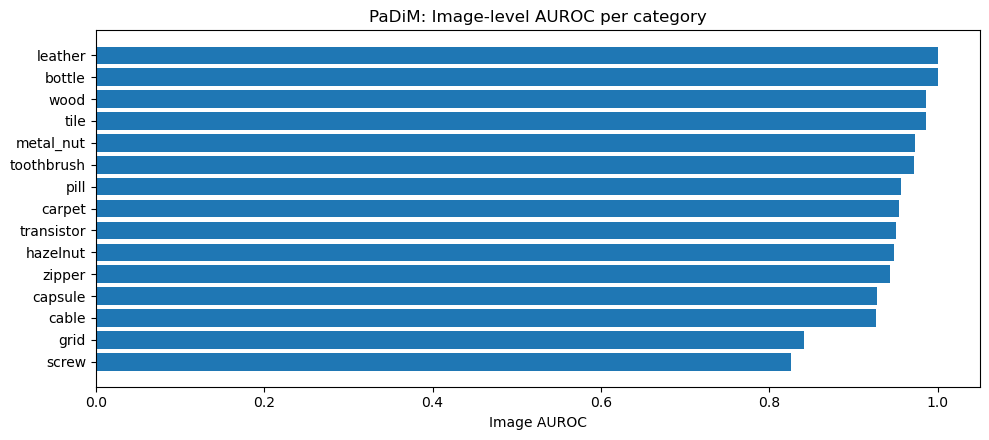

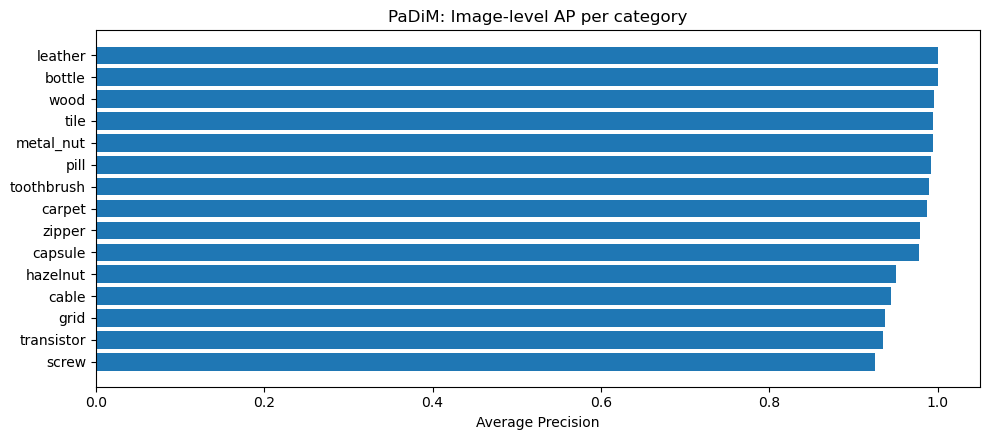

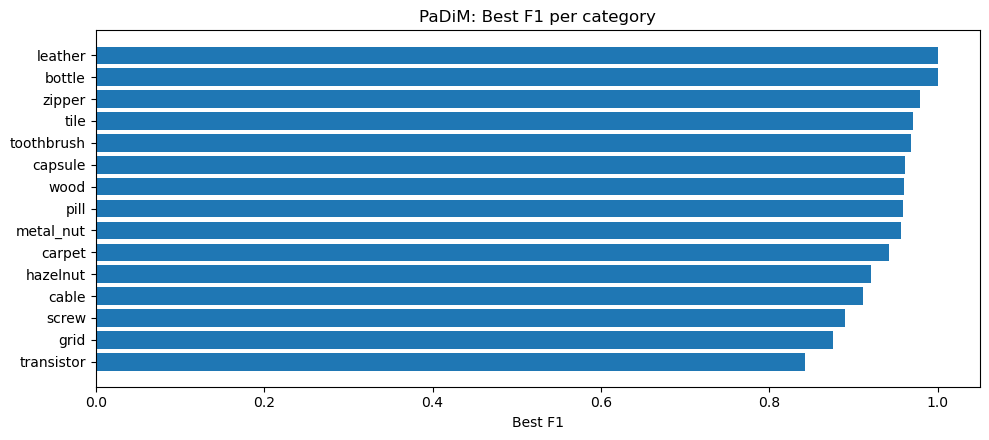

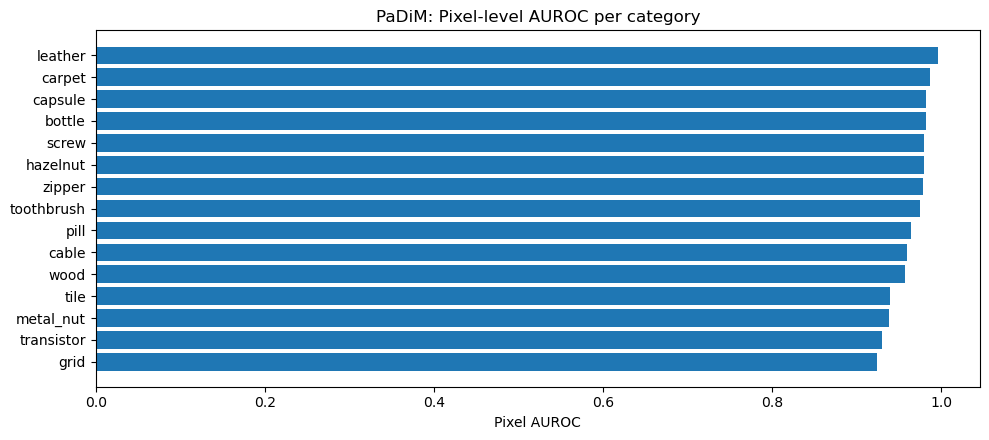

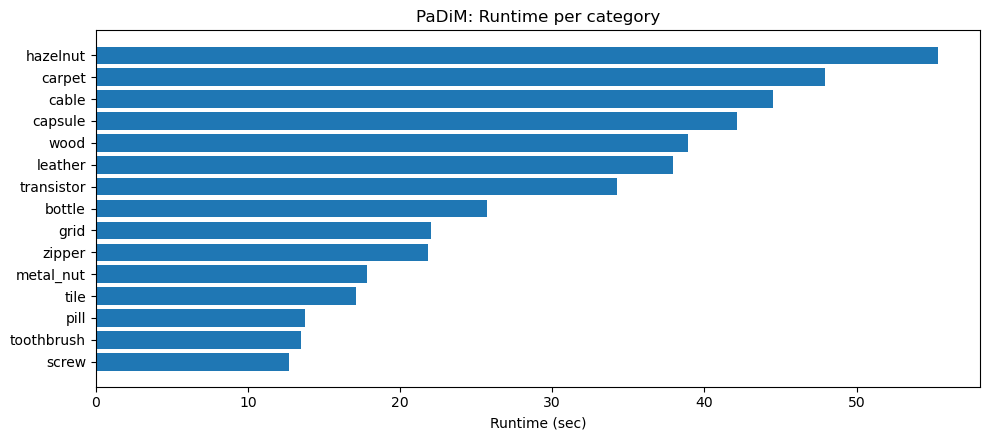

...

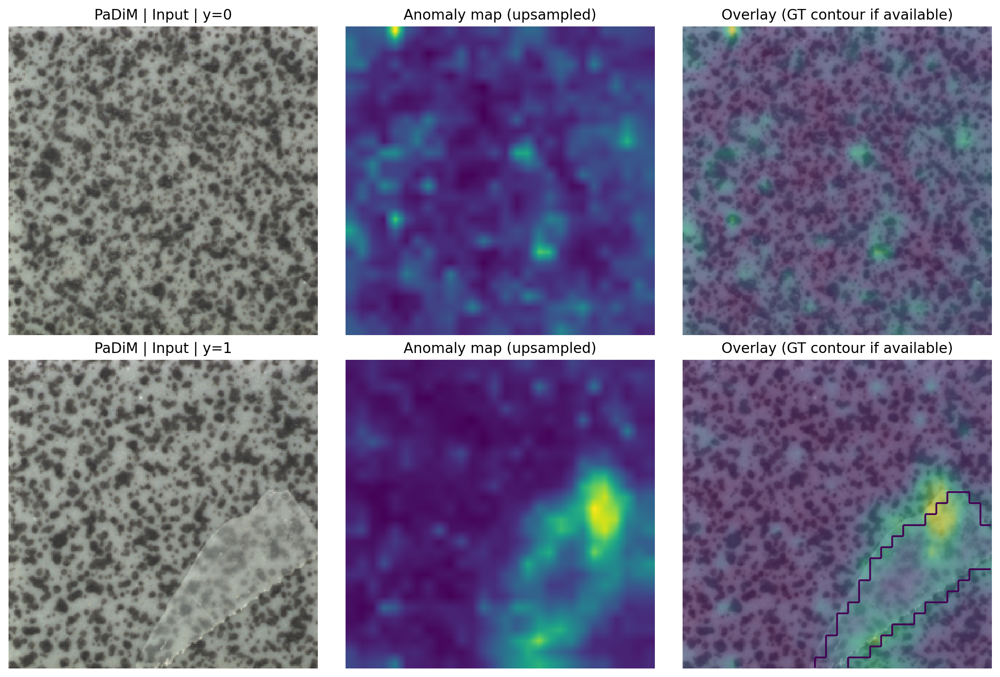

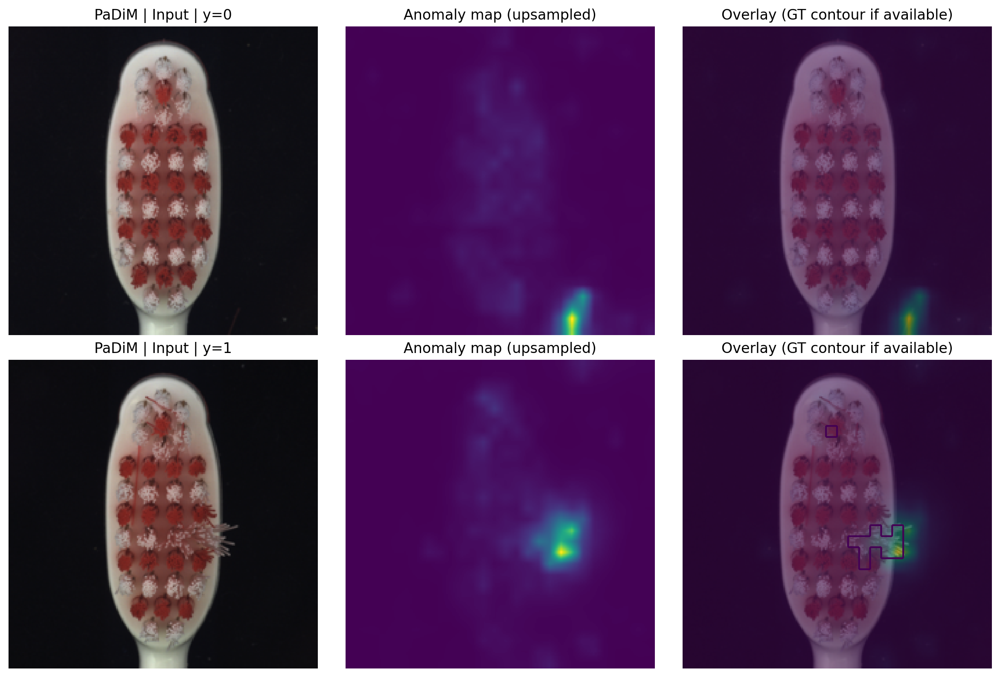

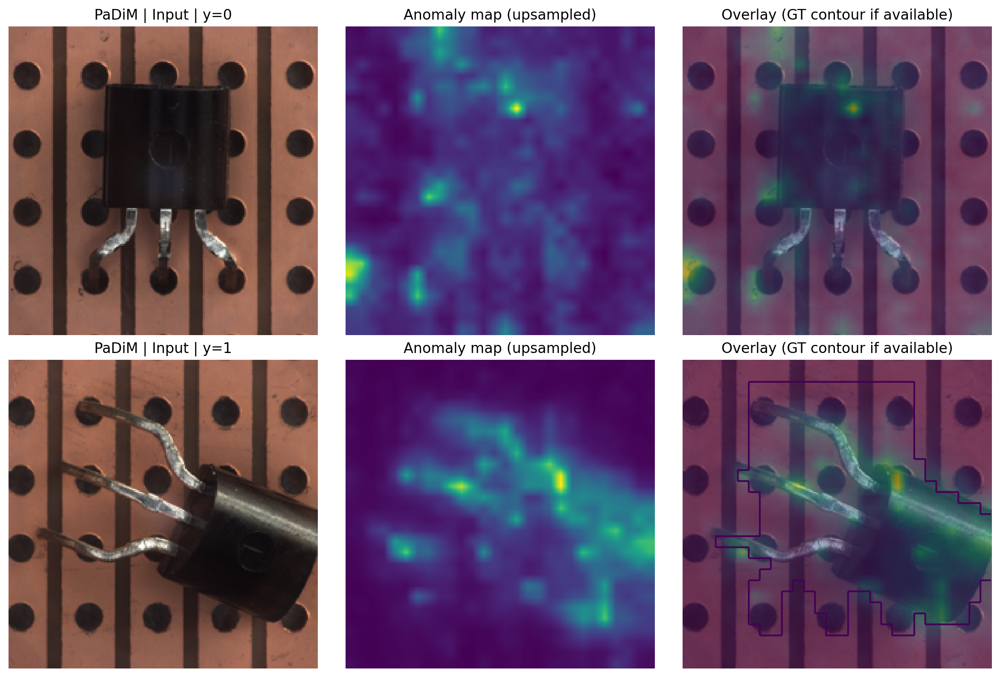

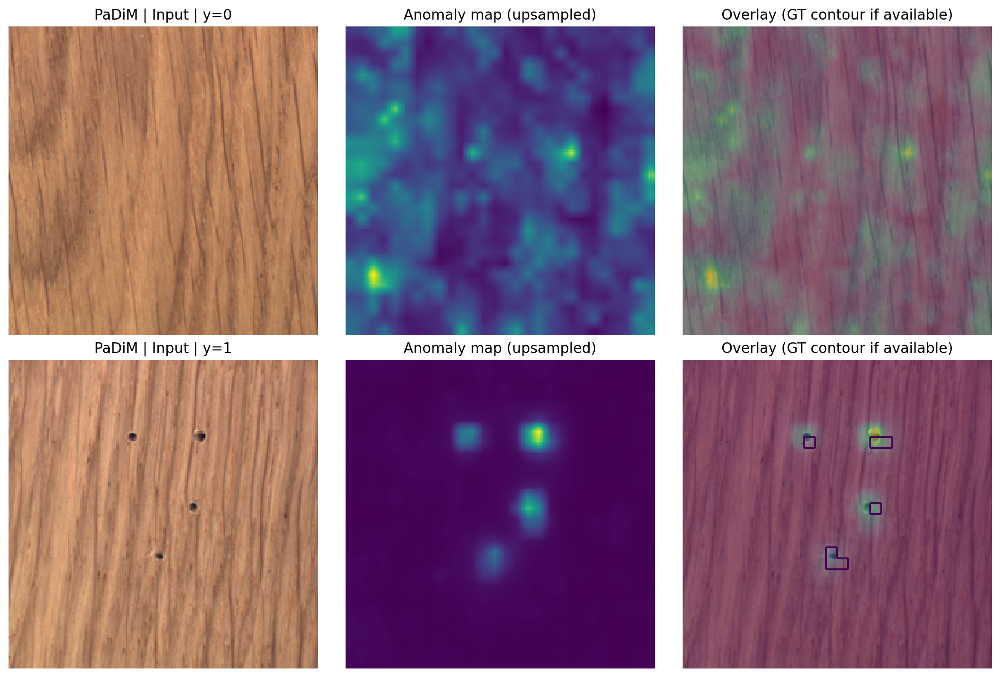

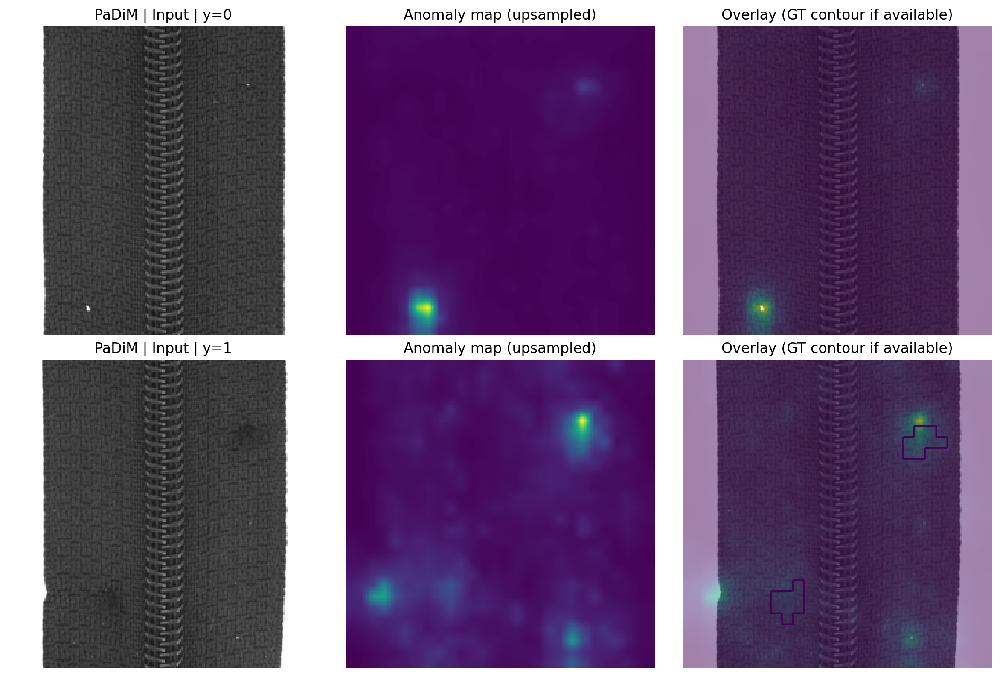

In [37]:
padim_report = summarize_padim_outputs(padim_out_by_category, name='PaDiM')
show_model_tables(padim_report)
plot_model_charts(padim_report)

plot_model_qualitative(
    padim_report,
    padim_out_by_category,
    QUAL_SAMPLE_PATHS_BY_CAT,
    mode='padim',
    categories=padim_report.qual_categories,
    n_per_cat=6,
    seed=SEED,
)

In [38]:
# If you haven't implemented the student method yet, this notebook can still run end-to-end.
# We create a dummy `student_out_by_cat` that:
# - uses the same `paths` as PaDiM
# - perturbs PaDiM `score_maps`
# - computes `scores` from the perturbed maps
# - sets a plausible `runtime_sec`

def make_dummy_student_out_by_cat(
    padim_out_by_category: Dict[str, Dict[str, object]],
    *,
    seed: int = 0,
    noise: float = 0.15,
) -> Dict[str, Dict[str, object]]:
    rng = np.random.RandomState(seed)
    out: Dict[str, Dict[str, object]] = {}

    for cat, p in padim_out_by_category.items():
        paths = list(p['paths'])
        pmaps = np.asarray(p['score_maps'], dtype=np.float32)

        smaps = pmaps + noise * rng.randn(*pmaps.shape).astype(np.float32)
        smaps = np.stack([normalize_01(m) for m in smaps], axis=0).astype(np.float32)

        scores = np.asarray([aggregate_image_score(m) for m in smaps], dtype=np.float32)
        scores = normalize_01(scores)

        runtime_sec = float(p.get('runtime_sec', 0.0)) * 0.8 + float(rng.rand() * 0.02)

        out[cat] = {
            'paths': paths,
            'scores': scores.tolist(),
            'score_maps': smaps,
            'runtime_sec': runtime_sec,
        }

    return out

In [39]:
if student_out_by_cat is None:
    student_out_by_cat = make_dummy_student_out_by_cat(padim_out_by_category, seed=0, noise=0.15)
    print('Generated dummy student_out_by_cat (so the notebook can run without a student implementation).')

In [40]:
# After implementing `StudentMethod`, run it per category and store outputs here:
#   student_out_by_cat[category] = student.predict(test_loader)
#
# The `predict` output must align with the test loader ordering (paths/scores/score_maps).

,category,n_test_total,n_test_good,n_test_anom,auroc,ap,best_f1,best_thr,bal_acc,pixel_auroc,pixel_best_dice,runtime_sec
0,wood,79,19,60,0.971053,0.991932,0.957983,0.147823,0.922368,0.643149,0.233573,3.762539
1,tile,117,33,84,0.898990,0.960535,0.898204,0.146409,0.825216,0.604376,0.288174,9.723538
2,hazelnut,110,40,70,0.780000,0.879271,0.813333,0.107944,0.698214,0.891809,0.413621,11.326487
3,transistor,100,60,40,0.636667,0.565412,0.597701,0.258733,0.650000,0.615609,0.232536,10.401788
4,leather,124,32,92,0.598845,0.860274,0.851852,0.000000,0.500000,0.638551,0.236109,5.459249
5,bottle,83,20,63,0.592857,0.830260,0.877698,0.248947,0.609127,0.701084,0.237446,8.323258
6,toothbrush,42,12,30,0.586111,0.758414,0.833333,0.000000,0.500000,0.764058,0.129418,3.943037
7,zipper,151,32,119,0.574317,0.815484,0.881481,0.000000,0.500000,0.728858,0.165242,8.466013
8,grid,78,21,57,0.570593,0.823894,0.844444,0.000000,0.500000,0.526465,0.070937,4.580625
9,pill,167,26,141,0.566012,0.865023,0.915584,0.000000,0.500000,0.519994,0.176406,11.982926


,scope,auroc,ap,best_f1,bal_acc,pixel_auroc,pixel_best_dice,runtime_sec
0,macro_mean_across_categories,0.564736,0.787512,0.850068,0.580903,0.683823,0.196433,8.594431
1,micro_all_test_images,0.578589,0.769054,0.843446,0.500000,0.683823,0.196433,8.594431


Qualitative categories (best/middle/worst): ['wood', 'zipper', 'screw']
Student | category: bottle


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1199296106.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved: outputs\qualitative\student_bottle.png
Student | category: cable


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\1445182827.py:180: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


... (10 outputs left out)

Saved: outputs\qualitative\student_toothbrush.png
Student | category: transistor


Saved: outputs\qualitative\student_transistor.png
Student | category: wood


Saved: outputs\qualitative\student_wood.png
Student | category: zipper


Saved: outputs\qualitative\student_zipper.png


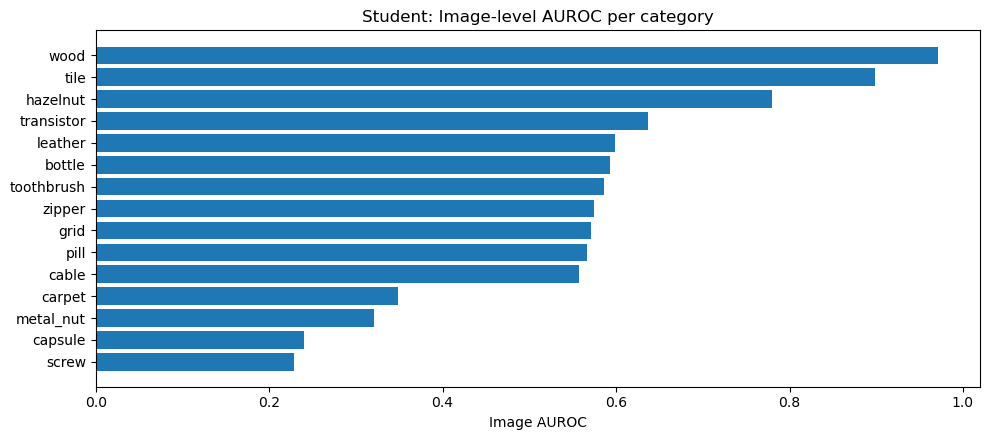

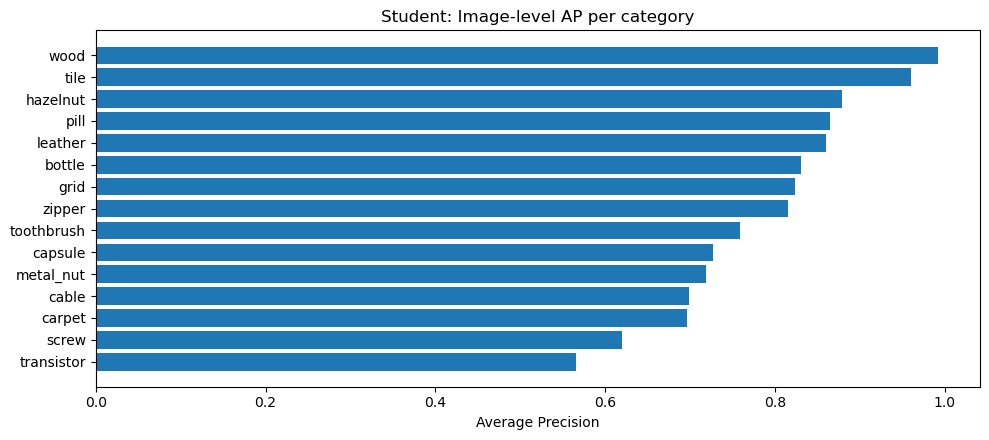

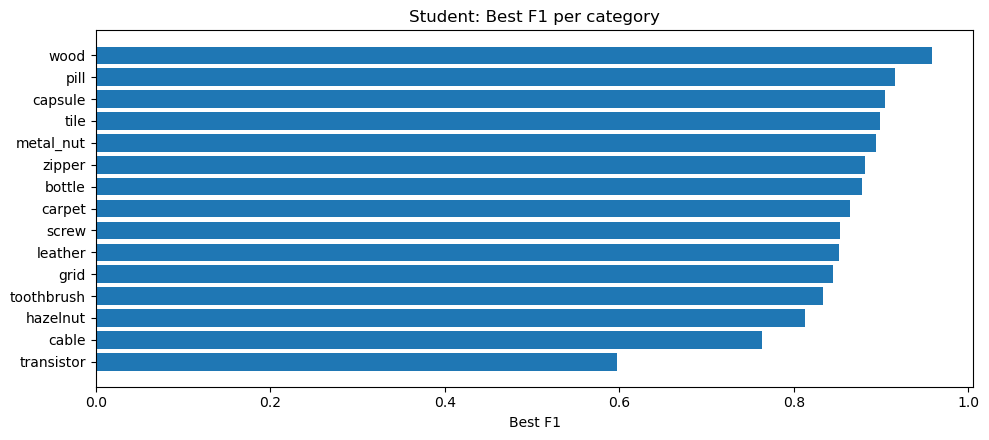

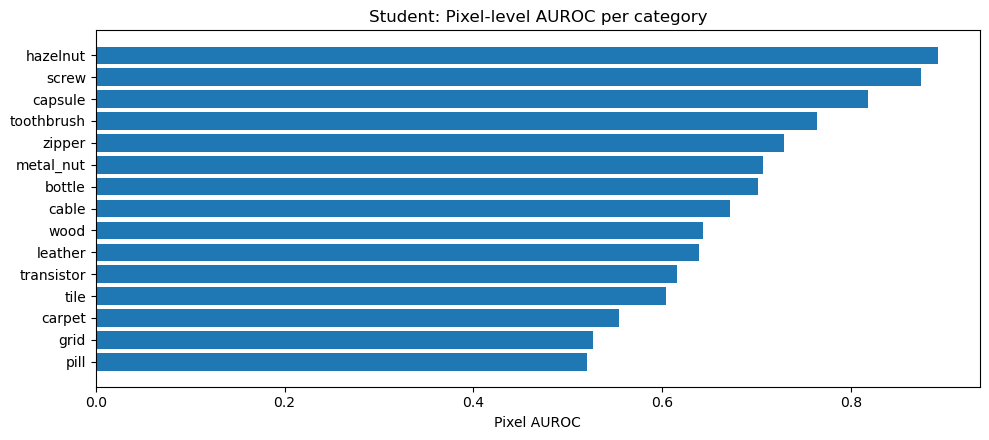

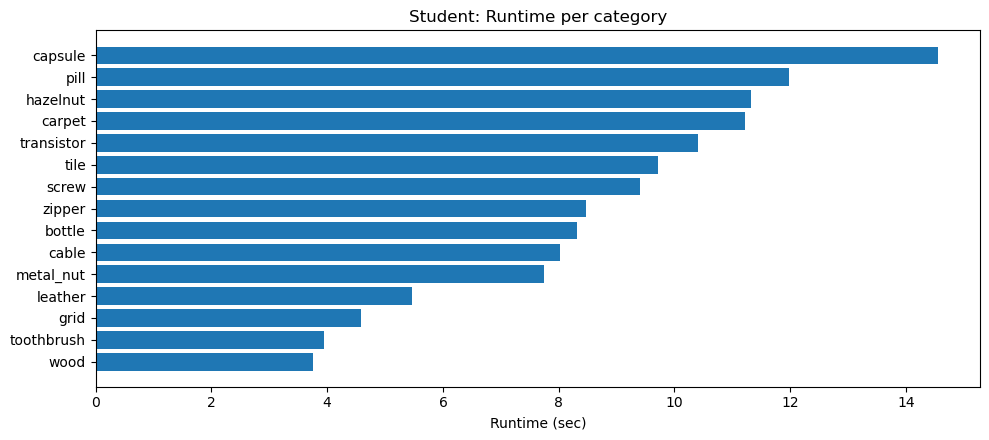

...

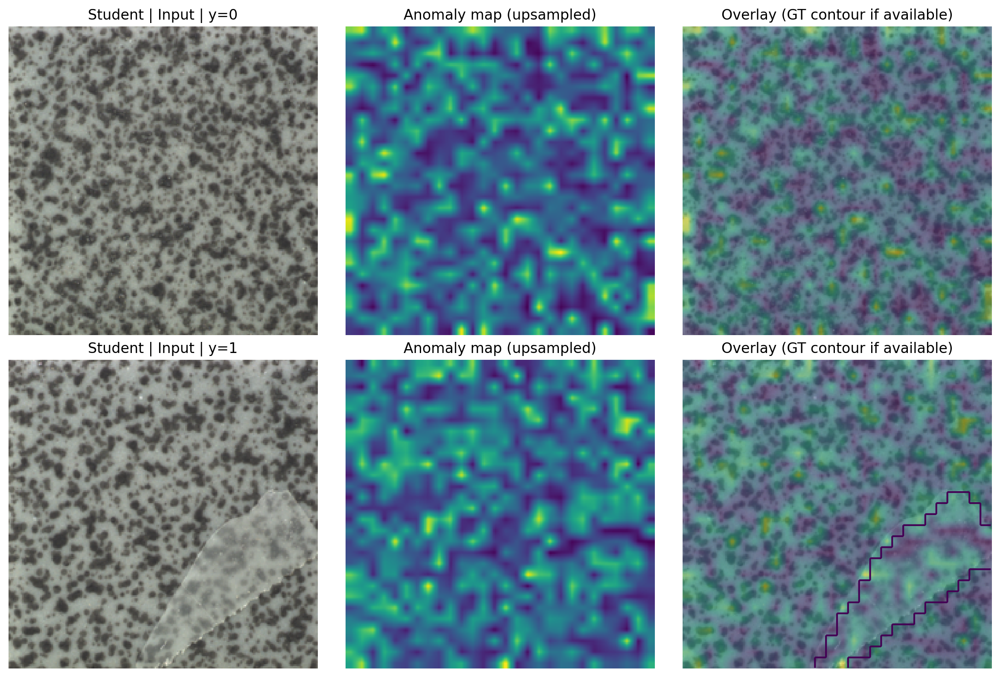

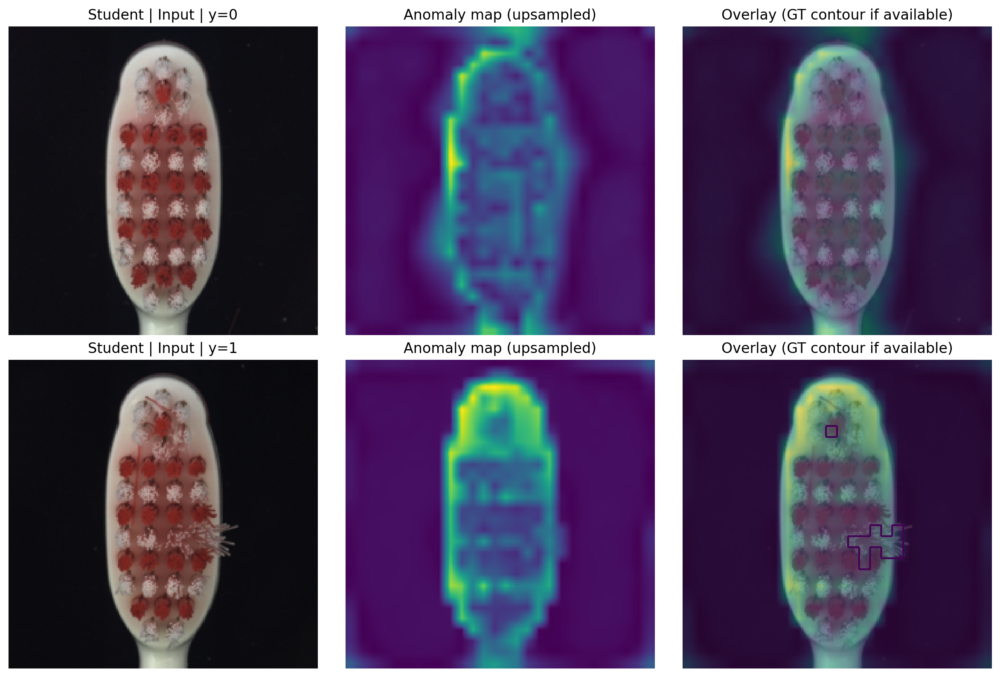

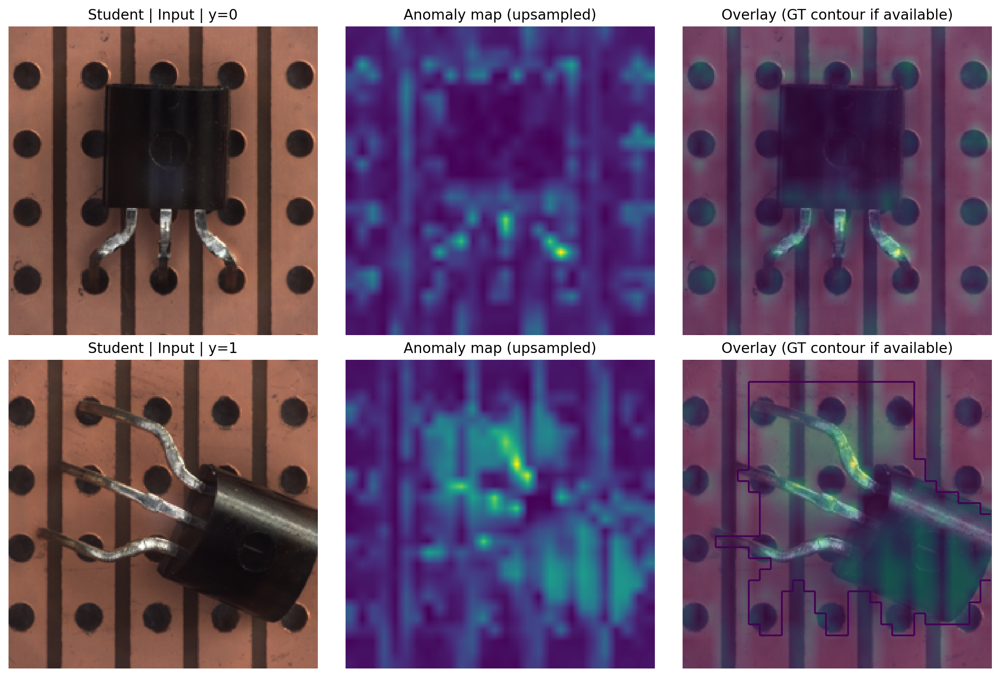

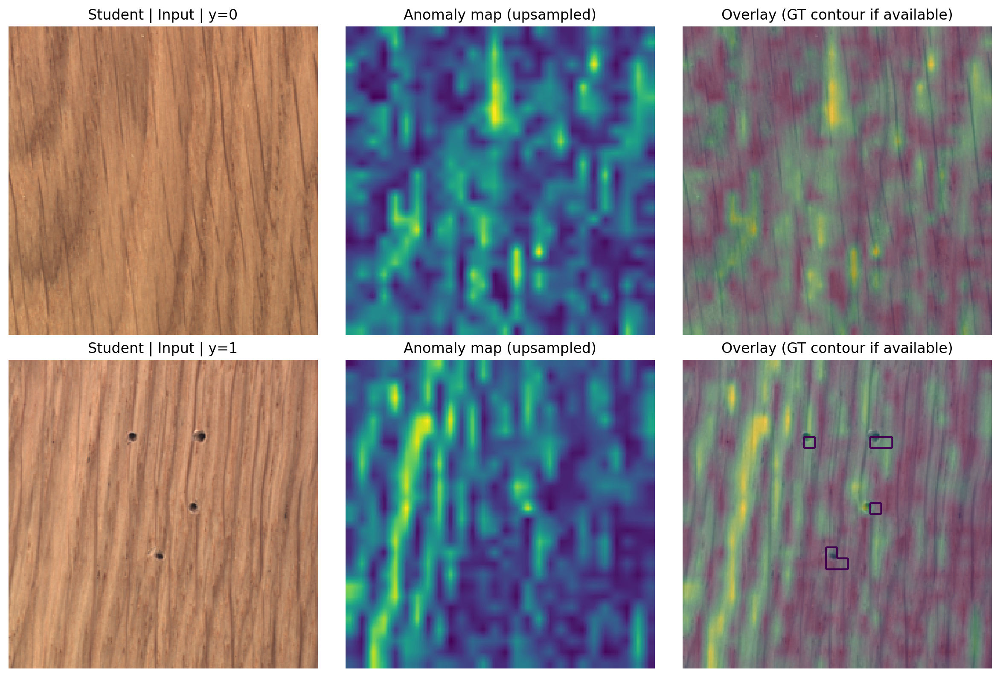

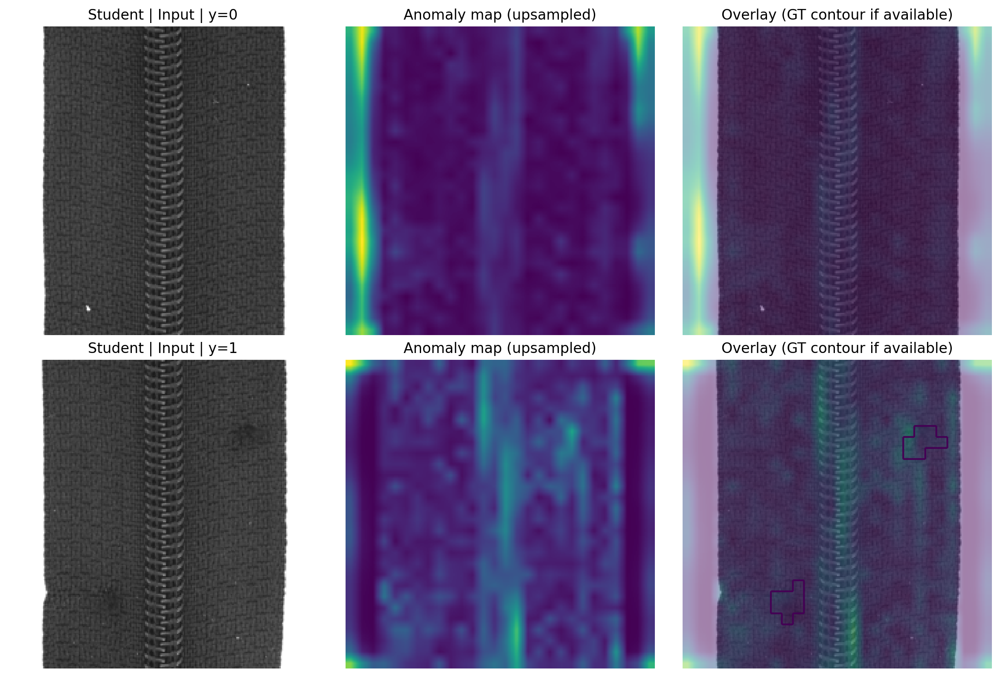

In [41]:
student_report = summarize_student_outputs(student_out_by_cat, padim_out_by_category, name='Student')
show_model_tables(student_report)
plot_model_charts(student_report)

# Qualitative: same fixed samples as PaDiM
plot_model_qualitative(
    student_report,
    student_out_by_cat,
    QUAL_SAMPLE_PATHS_BY_CAT,
    mode='student',
    gt_out_by_cat=padim_out_by_category,  # for GT contours/labels
    categories=student_report.qual_categories,
    n_per_cat=6,
    seed=SEED,
)

## 9) PaDiM vs Student comparison (4 points, just running cells, no TODOs)

We compare PaDiM vs the student method:
- per-category metrics (side-by-side + deltas)
- overall micro/macro summary (side-by-side + deltas)
- integrated qualitative comparison on the **same fixed samples**

In [42]:
COMPARISON_METRICS = [
    'auroc',
    'ap',
    'best_f1',
    'bal_acc',
    'pixel_auroc',
    'pixel_best_dice',
    'runtime_sec',
]


def build_category_comparison_df(
    padim_report: ModelReport,
    student_report: ModelReport,
    metrics: List[str] = COMPARISON_METRICS,
) -> pd.DataFrame:
    """Merge per-category tables and add delta columns (student - padim)."""
    p = padim_report.df_cat.copy()
    s = student_report.df_cat.copy()

    keep_cols = ['category'] + [m for m in metrics if m in p.columns]
    p = p[keep_cols].rename(columns={m: f'padim_{m}' for m in keep_cols if m != 'category'})

    keep_cols_s = ['category'] + [m for m in metrics if m in s.columns]
    s = s[keep_cols_s].rename(columns={m: f'student_{m}' for m in keep_cols_s if m != 'category'})

    df = p.merge(s, on='category', how='inner')

    for m in metrics:
        pm = f'padim_{m}'
        sm = f'student_{m}'
        if pm in df.columns and sm in df.columns:
            df[f'delta_{m}'] = pd.to_numeric(df[sm], errors='coerce') - pd.to_numeric(df[pm], errors='coerce')

    return df.sort_values('delta_auroc', ascending=False) if 'delta_auroc' in df.columns else df


def build_overall_comparison_df(padim_report: ModelReport, student_report: ModelReport) -> pd.DataFrame:
    """Build a 2-row table comparing macro and micro summaries."""
    def _row(df: pd.DataFrame, scope: str) -> pd.Series:
        r = df[df['scope'] == scope].iloc[0]
        return r

    scopes = ['macro_mean_across_categories', 'micro_all_test_images']
    rows = []

    for scope in scopes:
        pr = _row(padim_report.df_summary, scope)
        sr = _row(student_report.df_summary, scope)

        row = {'scope': scope}
        for m in COMPARISON_METRICS:
            if m in pr:
                row[f'padim_{m}'] = pr[m]
            if m in sr:
                row[f'student_{m}'] = sr[m]
            if f'padim_{m}' in row and f'student_{m}' in row:
                row[f'delta_{m}'] = _safe_float(row[f'student_{m}']) - _safe_float(row[f'padim_{m}'])
        rows.append(row)

    return pd.DataFrame(rows)


def plot_delta_bar(df_cat_cmp: pd.DataFrame, metric: str, title: Optional[str] = None) -> None:
    """Plot per-category delta bars for one metric (student - padim)."""
    col = f'delta_{metric}'
    if col not in df_cat_cmp.columns:
        print(f'No column {col} in comparison table.')
        return

    d = df_cat_cmp[['category', col]].copy()
    d[col] = pd.to_numeric(d[col], errors='coerce')
    d = d.dropna(subset=[col]).sort_values(col, ascending=True)

    if len(d) == 0:
        print(f'[{metric}] nothing to plot.')
        return

    plt.figure(figsize=(10, max(4, 0.3 * len(d))))
    plt.barh(d['category'], d[col])
    plt.xlabel(f'Delta {metric} (student - padim)')
    plt.title(title or f'Delta {metric} per category')
    plt.tight_layout()
    plt.show()


Per-category comparison (student - padim deltas included):


,category,padim_auroc,padim_ap,padim_best_f1,padim_bal_acc,padim_pixel_auroc,padim_pixel_best_dice,padim_runtime_sec,student_auroc,student_ap,...,student_pixel_auroc,student_pixel_best_dice,student_runtime_sec,delta_auroc,delta_ap,delta_best_f1,delta_bal_acc,delta_pixel_auroc,delta_pixel_best_dice,delta_runtime_sec
2,wood,0.985965,0.995700,0.960000,0.868421,0.956943,0.562523,38.906728,0.971053,0.991932,...,0.643149,0.233573,3.762539,-0.014912,-0.003768,-0.002017,0.053947,-0.313794,-0.328949,-35.144189
3,tile,0.985570,0.994228,0.970414,0.942641,0.939006,0.607552,17.137175,0.898990,0.960535,...,0.604376,0.288174,9.723538,-0.086580,-0.033693,-0.072211,-0.117424,-0.334630,-0.319379,-7.413637
9,hazelnut,0.947857,0.950556,0.920863,0.894643,0.979414,0.631204,55.348918,0.780000,0.879271,...,0.891809,0.413621,11.326487,-0.167857,-0.071285,-0.107530,-0.196429,-0.087604,-0.217582,-44.022432
13,grid,0.840434,0.936775,0.876033,0.703008,0.924427,0.344436,22.014217,0.570593,0.823894,...,0.526465,0.070937,4.580625,-0.269841,-0.112881,-0.031589,-0.203008,-0.397962,-0.273499,-17.433592
8,transistor,0.950000,0.934321,0.842105,0.875000,0.929872,0.557835,34.286859,0.636667,0.565412,...,0.615609,0.232536,10.401788,-0.313333,-0.368909,-0.244404,-0.225000,-0.314262,-0.325299,-23.885071
10,zipper,0.943015,0.979318,0.979253,0.933298,0.978434,0.629692,21.810637,0.574317,0.815484,...,0.728858,0.165242,8.466013,-0.368697,-0.163834,-0.097772,-0.433298,-0.249576,-0.464449,-13.344624
12,cable,0.926349,0.944529,0.910995,0.869378,0.959167,0.577986,44.531596,0.556784,0.699093,...,0.671691,0.175464,8.020882,-0.369565,-0.245436,-0.147509,-0.360757,-0.287476,-0.402522,-36.510713
5,toothbrush,0.972222,0.988864,0.967742,0.916667,0.974841,0.472922,13.515557,0.586111,0.758414,...,0.764058,0.129418,3.943037,-0.386111,-0.230450,-0.134409,-0.416667,-0.210783,-0.343504,-9.572519
6,pill,0.956083,0.992196,0.958042,0.831969,0.964519,0.488538,13.777666,0.566012,0.865023,...,0.519994,0.176406,11.982926,-0.390071,-0.127173,-0.042458,-0.331969,-0.444525,-0.312132,-1.794739
1,leather,1.000000,1.000000,1.000000,1.000000,0.995932,0.704577,37.907213,0.598845,0.860274,...,0.638551,0.236109,5.459249,-0.401155,-0.139726,-0.148148,-0.500000,-0.357381,-0.468469,-32.447964


Overall comparison (macro + micro):


,scope,padim_auroc,student_auroc,delta_auroc,padim_ap,student_ap,delta_ap,padim_best_f1,student_best_f1,delta_best_f1,...,delta_bal_acc,padim_pixel_auroc,student_pixel_auroc,delta_pixel_auroc,padim_pixel_best_dice,student_pixel_best_dice,delta_pixel_best_dice,padim_runtime_sec,student_runtime_sec,delta_runtime_sec
0,macro_mean_across_categories,0.945770,0.564736,-0.381034,0.973402,0.787512,-0.185890,0.942306,0.850068,-0.092238,...,-0.293346,0.964669,0.683823,-0.280846,0.57276,0.196433,-0.376327,29.700181,8.594431,-21.10575
1,micro_all_test_images,0.896866,0.578589,-0.318277,0.953587,0.769054,-0.184532,0.911787,0.843446,-0.068340,...,-0.264032,0.964669,0.683823,-0.280846,0.57276,0.196433,-0.376327,29.700181,8.594431,-21.10575


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\598174199.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\598174199.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\598174199.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\moham\AppData\Local\Temp\ipykernel_25368\598174199.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


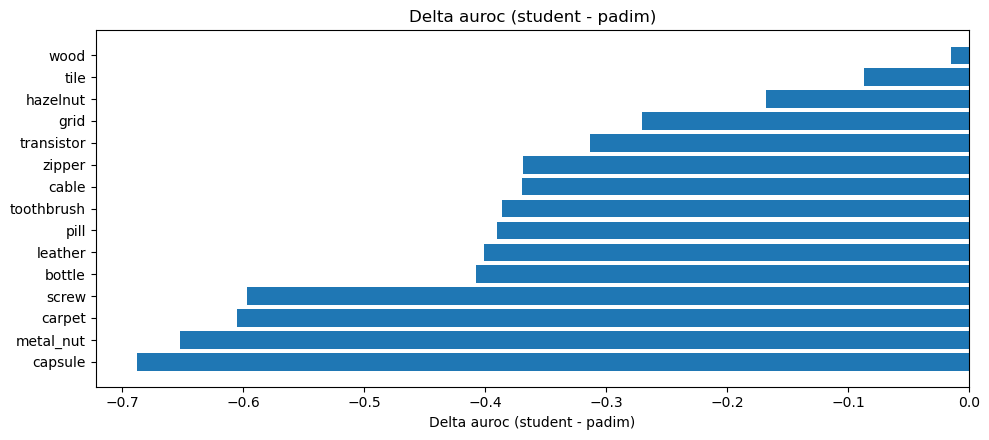

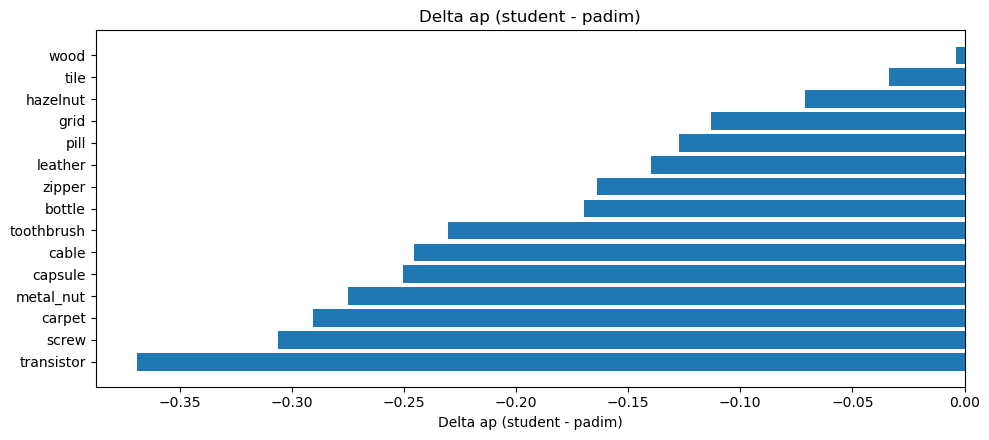

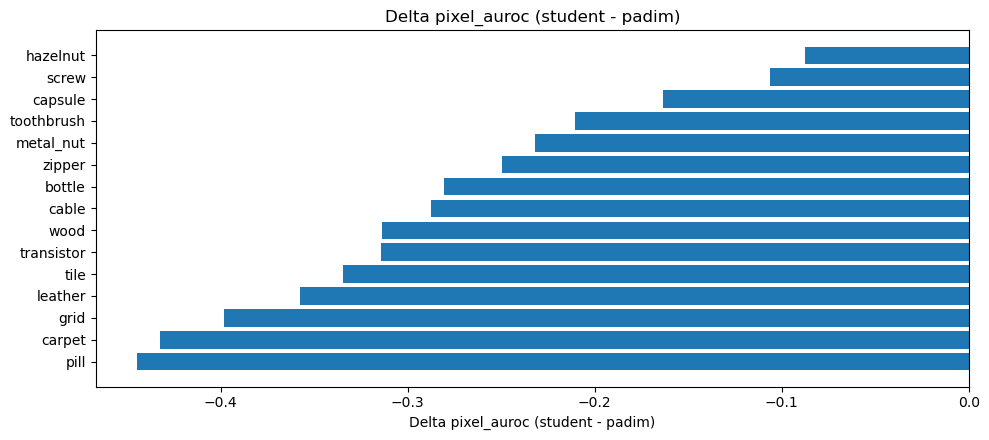

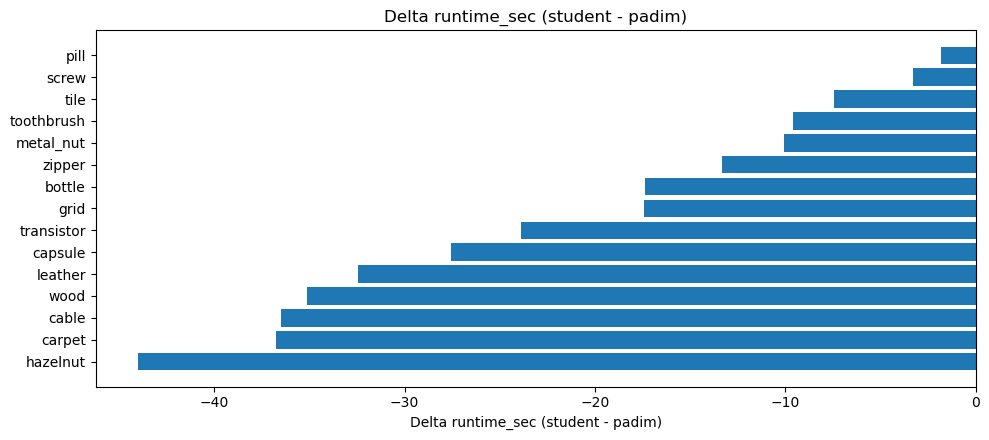

In [43]:
# Quantitative comparison: PaDiM vs Student

assert 'padim_report' in globals(), 'Run the PaDiM reporting cell first (padim_report).'
assert 'student_report' in globals(), 'Run the student reporting cell first (student_report).'

df_cat_cmp = build_category_comparison_df(padim_report, student_report)
df_overall_cmp = build_overall_comparison_df(padim_report, student_report)

print('Per-category comparison (student - padim deltas included):')
display(df_cat_cmp)

print('Overall comparison (macro + micro):')
display(df_overall_cmp)

# A few standard delta plots
plot_delta_bar(df_cat_cmp, 'auroc', 'Delta Image AUROC (student - padim)')
plot_delta_bar(df_cat_cmp, 'ap', 'Delta Image AP (student - padim)')
plot_delta_bar(df_cat_cmp, 'pixel_auroc', 'Delta Pixel AUROC (student - padim)')
plot_delta_bar(df_cat_cmp, 'runtime_sec', 'Delta Runtime (student - padim)')


### Integrated qualitative comparison (same fixed samples)

For the same images, show:

**Input | PaDiM overlay | Student overlay**

This makes it easy to see whether the student method localizes defects similarly (or better).


In [44]:
def plot_padim_vs_student_qualitative(
    padim_report: ModelReport,
    student_report: ModelReport,
    padim_out_by_cat: Dict[str, Dict[str, object]],
    student_out_by_cat: Dict[str, Dict[str, object]],
    fixed_samples_by_cat: Dict[str, List[str]],
    *,
    categories: Optional[List[str]] = None,
    n_per_cat: int = 6,
    seed: int = 0,
    vis_size: tuple[int, int] = (224, 224),
    save_dir: Optional[str] = './outputs/qualitative',
    save_dpi: int = 200,
):
    """Integrated qualitative comparison on the SAME fixed samples.

    For each category, shows rows of fixed samples with 3 columns:
      1) Input image
      2) PaDiM anomaly map overlay (+ GT contour if available)
      3) Student anomaly map overlay (+ GT contour if available)

    Notes:
      - Assumes student_out_by_cat[cat]['score_maps'] exists (required).
      - Uses PaDiM masks/labels for GT contours and y=0/1.
    """
    from pathlib import Path
    from PIL import Image
    import matplotlib.pyplot as plt
    import numpy as np
    import torch
    import torch.nn.functional as F

    H, W = vis_size

    def _mask_to_np_local(mask) -> Optional[np.ndarray]:
        """Convert a mask object to a float32 numpy array."""
        if mask is None:
            return None
        if torch.is_tensor(mask):
            m = mask.detach().cpu().numpy()
        else:
            m = np.asarray(mask)
        return m.astype(np.float32)

    def _upsample_map_to_vis(map2d: np.ndarray, size_hw: tuple[int, int]) -> np.ndarray:
        """Bilinear upsample for anomaly maps."""
        th = torch.tensor(map2d, dtype=torch.float32)[None, None]
        up = F.interpolate(th, size=size_hw, mode='bilinear', align_corners=False)
        return up.squeeze(0).squeeze(0).cpu().numpy().astype(np.float32)

    def _upsample_mask_to_vis(mask2d: np.ndarray, size_hw: tuple[int, int]) -> np.ndarray:
        """Nearest-neighbor upsample for binary masks."""
        th = torch.tensor(mask2d, dtype=torch.float32)[None, None]
        up = F.interpolate(th, size=size_hw, mode='nearest')
        up = up.squeeze(0).squeeze(0).cpu().numpy().astype(np.float32)
        return (up > 0.5).astype(np.float32)

    # Show all categories by default
    cats = categories or list(fixed_samples_by_cat.keys()) or sorted(list(padim_out_by_cat.keys()))
    rng = np.random.RandomState(seed)

    for cat in cats:
        if cat not in padim_out_by_cat or cat not in student_out_by_cat:
            continue

        pad = padim_out_by_cat[cat]
        stu = student_out_by_cat[cat]

        paths = [str(p) for p in pad.get('paths', [])]
        labels = list(pad.get('labels', []))
        masks = pad.get('masks', None)

        pad_maps = pad.get('score_maps', None)
        stu_maps = stu.get('score_maps', None)

        if stu_maps is None:
            raise ValueError(f"Student output for category '{cat}' is missing 'score_maps'.")

        # Use fixed samples when available; otherwise pick random indices.
        fixed = fixed_samples_by_cat.get(cat, [])
        fixed = [str(p) for p in fixed]
        idxs: List[int] = []

        if len(fixed) > 0:
            # Map fixed sample paths to indices in `paths` using suffix under /test/
            def _suffix_under_test(p: str) -> str:
                parts = Path(p).as_posix().split('/test/')
                return parts[-1] if len(parts) > 1 else Path(p).name

            idx_by_suffix = {_suffix_under_test(p): i for i, p in enumerate(paths)}
            for fp in fixed:
                key = _suffix_under_test(fp)
                if key in idx_by_suffix:
                    idxs.append(idx_by_suffix[key])
        else:
            idxs = list(range(len(paths)))
            rng.shuffle(idxs)

        idxs = idxs[:min(n_per_cat, len(idxs))]
        if len(idxs) == 0:
            continue

        plt.figure(figsize=(14, 4 * len(idxs)))
        for r, i in enumerate(idxs):
            img = Image.open(paths[i]).convert('RGB').resize((W, H))
            y = int(labels[i]) if i < len(labels) else 0

            # Prepare GT contour (only for anomalies)
            gt = None
            if y == 1 and masks is not None and i < len(masks) and masks[i] is not None:
                gt_np = _mask_to_np_local(masks[i])
                if gt_np is not None:
                    gt_np = gt_np.squeeze()
                    if gt_np.shape != (H, W):
                        gt_np = _upsample_mask_to_vis(gt_np, (H, W))
                    else:
                        gt_np = (gt_np > 0.5).astype(np.float32)
                    gt = gt_np

            def _get_map(maps_obj, idx: int) -> Optional[np.ndarray]:
                """Get a normalized HxW map for index idx."""
                if maps_obj is None or idx >= len(maps_obj):
                    return None
                m = np.asarray(maps_obj[idx]).astype(np.float32)
                if m.ndim != 2:
                    m = m.squeeze()
                if m.shape != (H, W):
                    m = _upsample_map_to_vis(m, (H, W))
                return normalize_01(m)

            pad_map = _get_map(pad_maps, i)
            stu_map = _get_map(stu_maps, i)

            # 1) Input
            plt.subplot(len(idxs), 3, 3 * r + 1)
            plt.imshow(img)
            plt.axis('off')
            plt.title(f'Input | y={y}')

            # 2) PaDiM overlay
            plt.subplot(len(idxs), 3, 3 * r + 2)
            plt.imshow(img)
            if pad_map is not None:
                plt.imshow(pad_map, alpha=0.5)
            else:
                plt.text(0.5, 0.5, 'No PaDiM score_maps', ha='center', va='center')
            if gt is not None:
                plt.contour(gt, levels=[0.5])
            plt.axis('off')
            plt.title('PaDiM overlay')

            # 3) Student overlay
            plt.subplot(len(idxs), 3, 3 * r + 3)
            plt.imshow(img)
            if stu_map is not None:
                plt.imshow(stu_map, alpha=0.5)
            else:
                plt.text(0.5, 0.5, 'No student score_maps', ha='center', va='center')
            if gt is not None:
                plt.contour(gt, levels=[0.5])
            plt.axis('off')
            plt.title('Student overlay')

        plt.suptitle(f'Qualitative comparison: {cat}', y=1.02, fontsize=14)
        plt.tight_layout()
        if save_dir is not None:
            out_dir = Path(save_dir)
            out_dir.mkdir(parents=True, exist_ok=True)
            out_path = out_dir / f'padim_vs_student_{cat}.png'
            plt.savefig(out_path, dpi=save_dpi, bbox_inches='tight')
            print('Saved:', out_path)
        plt.show()

Saved: outputs\qualitative\padim_vs_student_bottle.png


C:\Users\moham\AppData\Local\Temp\ipykernel_25368\662164735.py:172: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved: outputs\qualitative\padim_vs_student_cable.png


Saved: outputs\qualitative\padim_vs_student_capsule.png


Saved: outputs\qualitative\padim_vs_student_carpet.png


Saved: outputs\qualitative\padim_vs_student_grid.png


... (6 outputs left out)

Saved: outputs\qualitative\padim_vs_student_toothbrush.png


Saved: outputs\qualitative\padim_vs_student_transistor.png


Saved: outputs\qualitative\padim_vs_student_wood.png


Saved: outputs\qualitative\padim_vs_student_zipper.png


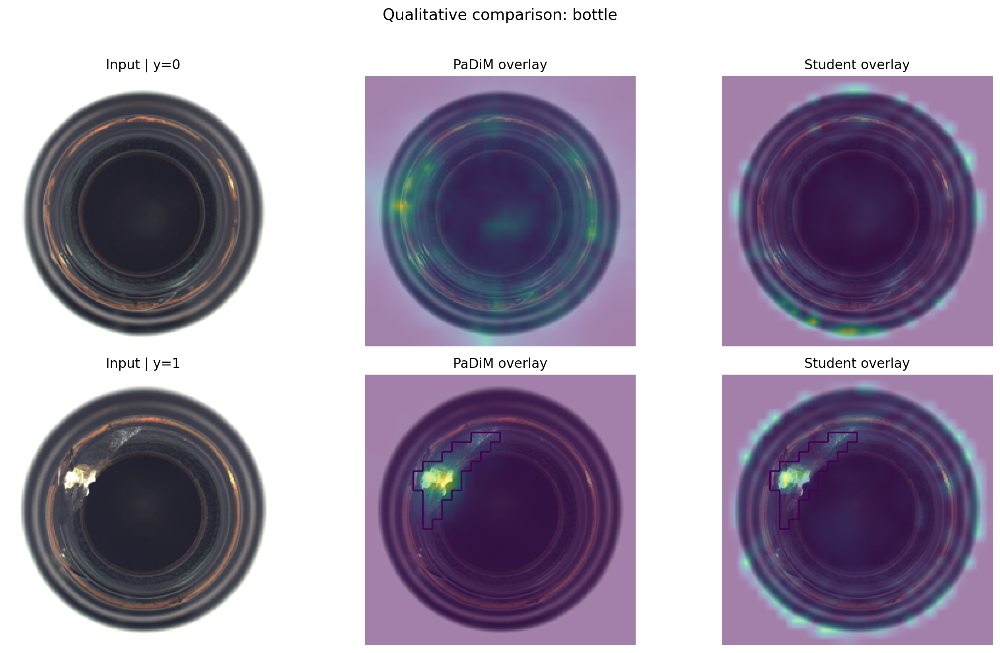

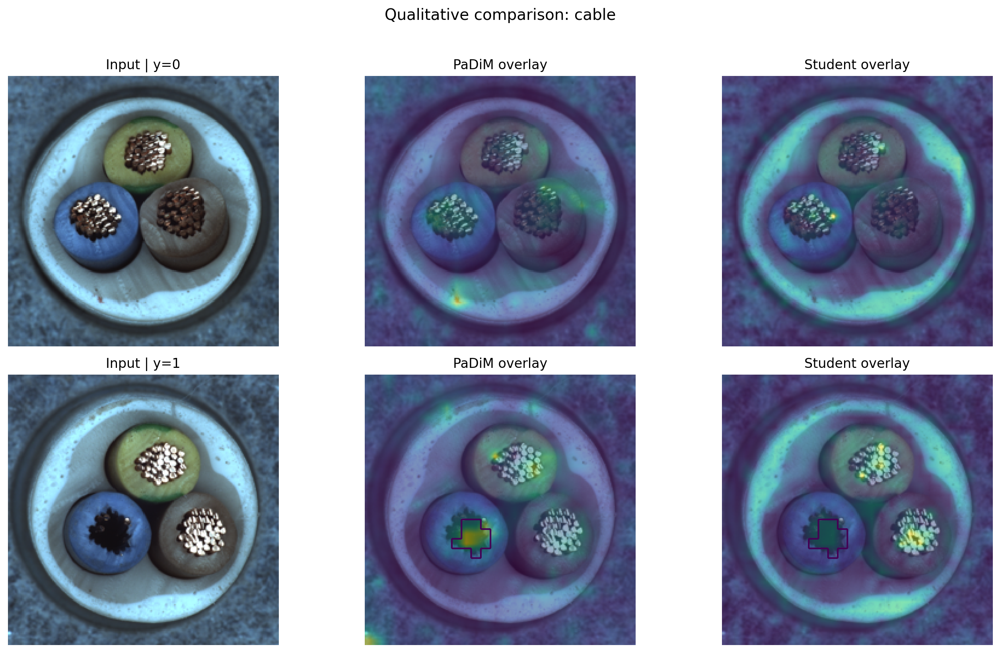

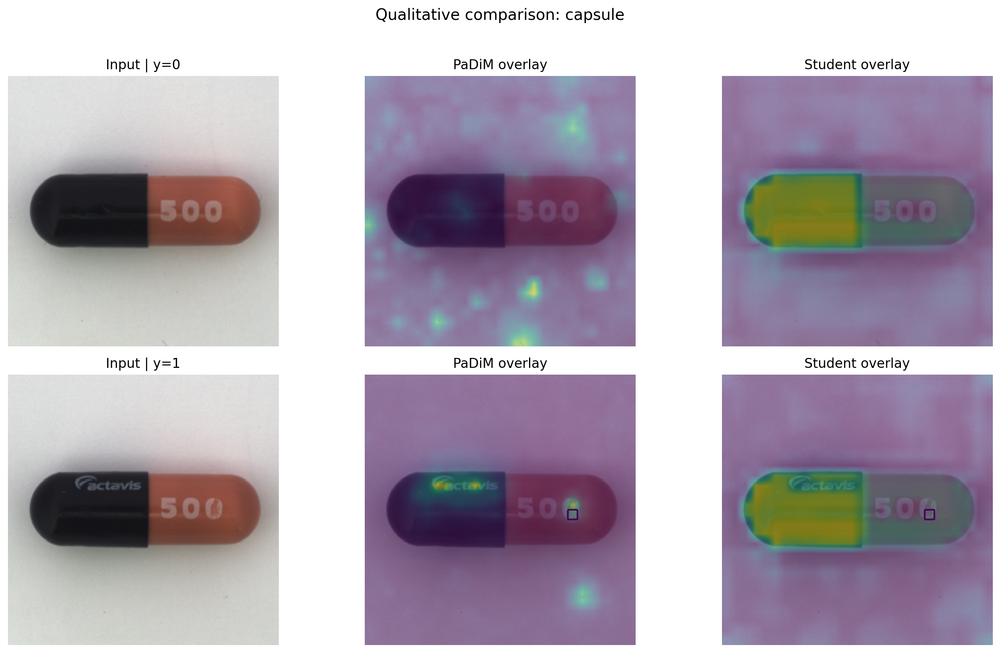

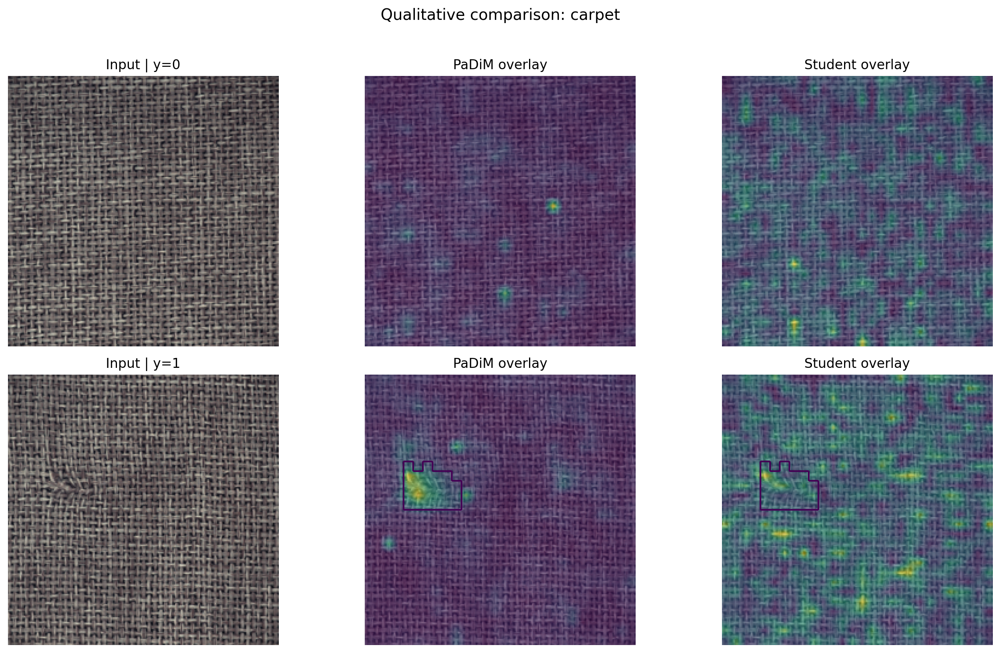

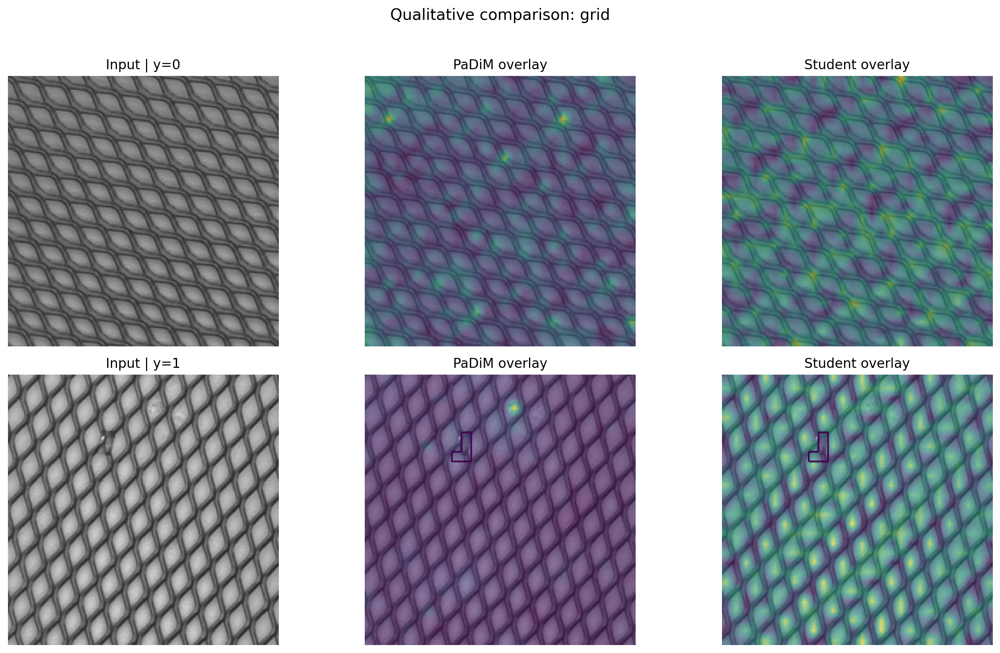

...

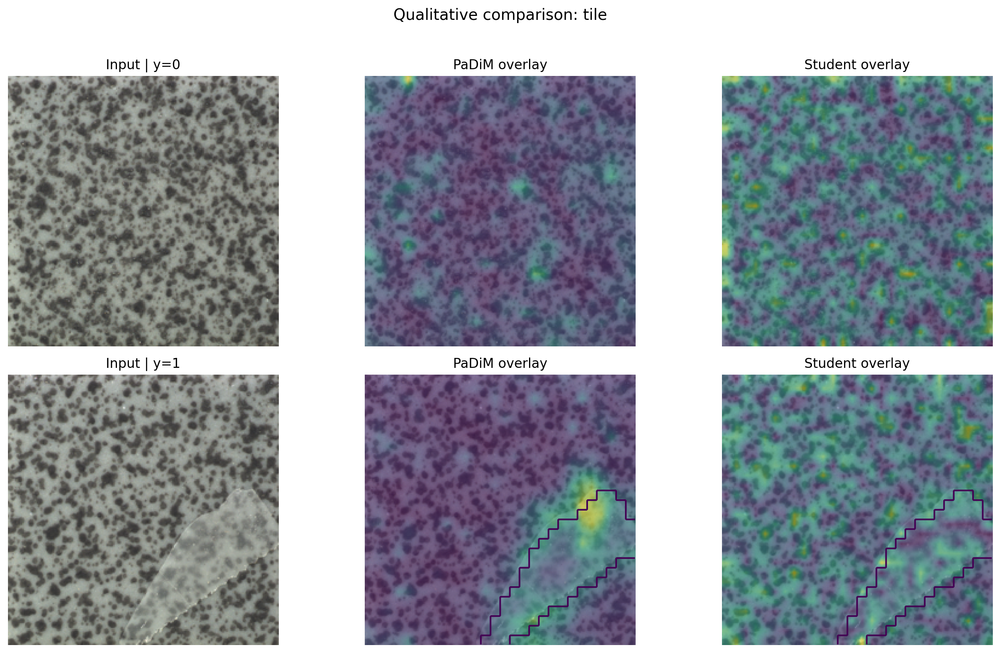

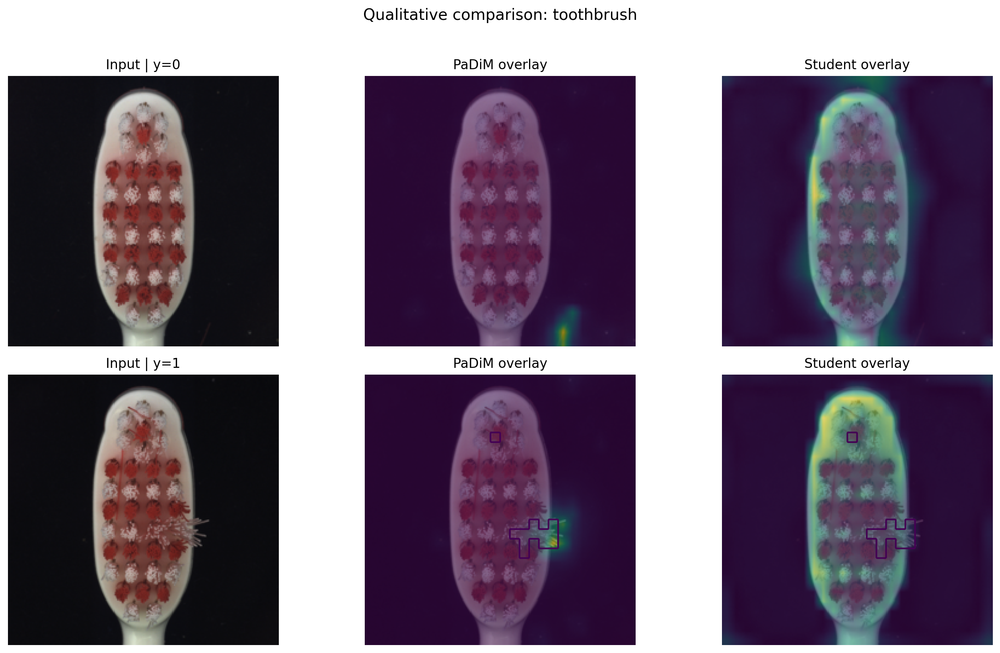

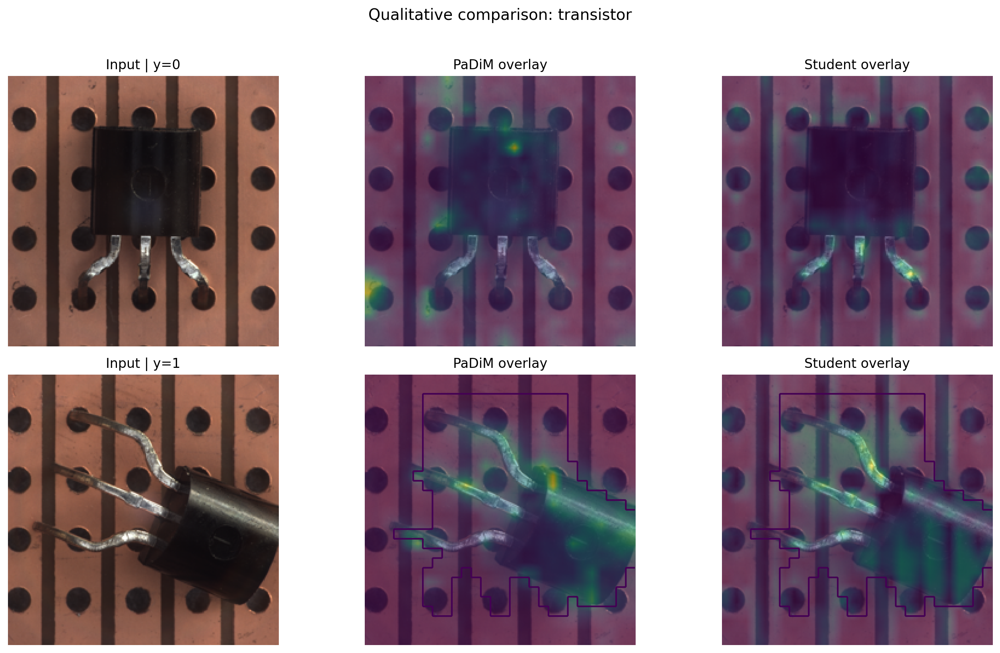

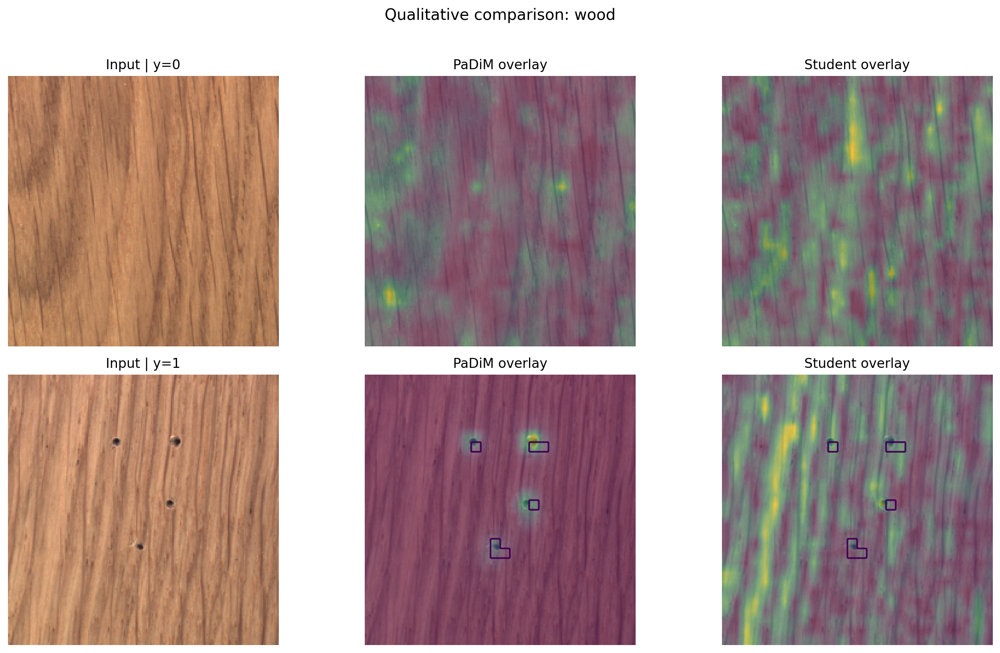

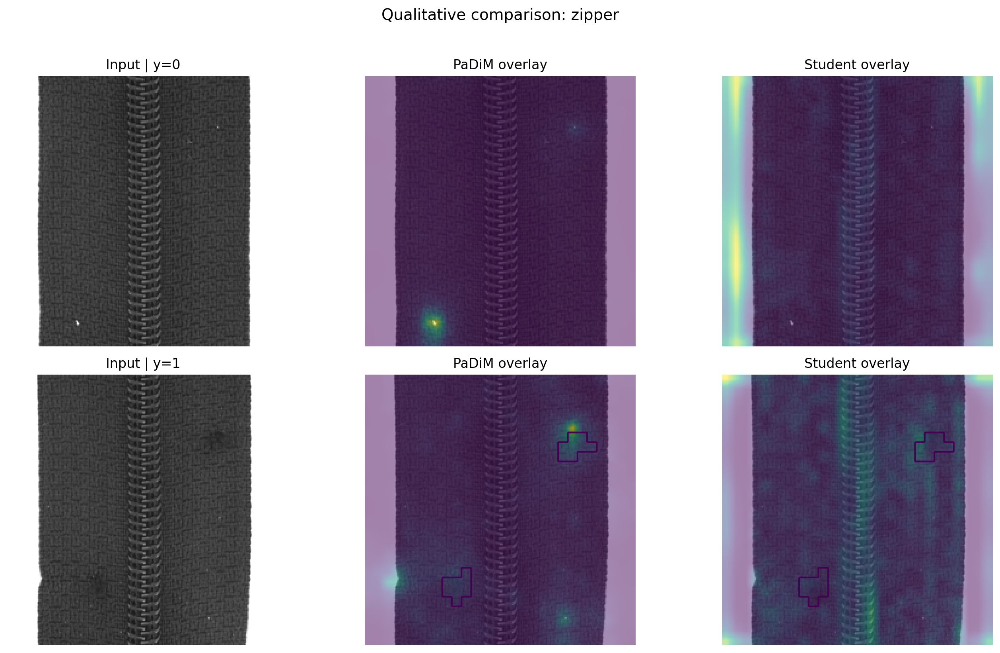

In [45]:
# Integrated qualitative comparison (Input | PaDiM | Student) on the SAME fixed samples
if 'padim_report' in globals() and 'student_report' in globals() and isinstance(student_out_by_cat, dict) and len(
        student_out_by_cat):
    plot_padim_vs_student_qualitative(
        padim_report,
        student_report,
        padim_out_by_category,
        student_out_by_cat,
        QUAL_SAMPLE_PATHS_BY_CAT,
        categories=CATEGORIES,
        n_per_cat=6,
        seed=SEED,
    )
else:
    print(
        'Run PaDiM + Student reports first (padim_report, student_report), and ensure student_out_by_cat is populated.')

## 10) Competitive leaderboard metrics

Because humans love turning nuanced work into a single number, here are **three comparable scores** (all in **[0, 1]**) designed for a competitive leaderboard.

All scores are computed from the **macro mean across categories** (so large categories do not dominate small ones).

### Definitions

1. **ImageScore**  
   `ImageScore = mean(Image AUROC, Image AP)`

2. **PixelScore**  
   `PixelScore = mean(Pixel AUROC, Pixel Best Dice)`  
   (If pixel metrics are unavailable, this becomes NaN.)

3. **OverallScore**  
   `OverallScore = mean(ImageScore, PixelScore)`  
   (Uses `nanmean`, so if PixelScore is NaN you effectively get ImageScore.)

### Extra credit points (3 teams)

| Rank | ImageScore bonus | PixelScore bonus | OverallScore bonus |
|------|-----------------:|-----------------:|-------------------:|
| 1st  |                4 |                5 |                  6 |
| 2nd  |                2 |                3 |                  4 |
| 3rd  |                0 |                1 |                  2 |

- **Total extra points** for a team is the **sum** of its bonuses across the three metrics:
  `extra_points = ImageScore_bonus + PixelScore_bonus + OverallScore_bonus`
  (Maximum extra = **15** points.)

To be ranked for each metric, your implementation must produce **valid, non-NaN values** for that metric.

In [46]:
def _nanmean_safe(values) -> float:
    arr = np.asarray(values, dtype=np.float32)
    finite = arr[np.isfinite(arr)]
    if finite.size == 0:
        return float('nan')
    return float(finite.mean())

def compute_leaderboard_scores(report: ModelReport, model_name: str) -> Dict[str, float]:
    """Compute compact leaderboard scores from a ModelReport.

    Uses the macro mean across categories from report.df_summary.
    Returns scores in [0, 1] when underlying metrics are defined that way.
    """
    df = report.df_summary
    macro = df.loc[df['scope'] == 'macro_mean_across_categories']
    if len(macro) == 0:
        raise ValueError(f'No macro summary row found in report.df_summary for model={model_name!r}.')
    macro = macro.iloc[0]

    # Image-level score: combine threshold-free AUROC with PR-focused AP
    image_score = _nanmean_safe([macro.get('auroc', np.nan), macro.get('ap', np.nan)])

    # Pixel-level score: combine AUROC with overlap-based Dice
    pixel_score = _nanmean_safe([macro.get('pixel_auroc', np.nan), macro.get('pixel_best_dice', np.nan)])

    # Overall score: combines image and pixel quality (nan-safe)
    overall_score = _nanmean_safe([image_score, pixel_score])

    runtime_sec = float(macro.get('runtime_sec', np.nan))

    return {
        'model': model_name,
        'ImageScore': image_score,
        'PixelScore': pixel_score,
        'OverallScore': overall_score,
        'runtime_sec': runtime_sec,
    }

In [47]:
# Example: compare PaDiM vs Student on this run
rows = []
if 'padim_report' in globals():
    rows.append(compute_leaderboard_scores(padim_report, 'PaDiM'))
if 'student_report' in globals():
    rows.append(compute_leaderboard_scores(student_report, 'Student'))

if len(rows) > 0:
    leaderboard_df = pd.DataFrame(rows).sort_values(
        by=['OverallScore', 'runtime_sec'],
        ascending=[False, True],
        kind='mergesort',
    ).reset_index(drop=True)

    display(leaderboard_df)
else:
    print('No reports found (expected padim_report and/or student_report). Run the evaluation cells above first.')

,model,ImageScore,PixelScore,OverallScore,runtime_sec
0,PaDiM,0.959586,0.768715,0.864150,29.700181
1,Student,0.676124,0.440128,0.558126,8.594431
